# Lab Two: Classification and Regression on Forest Cover Type

**MSDS 7331 Machine Learning I, Group 3**

Koosha Tabesh, Moinak Ghosh, Jacqueline Vu

Instructor: Dr. Nedelina Teneva

This lab builds on our Lab One analysis and the Mini Lab, both on the UCI Covertype dataset. We follow the CRISP-DM process (Shearer, 2000) and work on two tasks from the same data:

1. **Classification.** Predict `Cover_Type`, the dominant tree species of a 30 x 30 meter patch of forest, using all seven classes.
2. **Regression.** Predict `Elevation` in meters from the other terrain, distance, soil and wilderness features. `Cover_Type` is left out of the inputs for this task.

For classification we compare seven models: a decision tree, a random forest, a class weighted random forest, k nearest neighbors (KNN), histogram gradient boosting, extra trees and LightGBM. For regression we compare a random forest regressor, a KNN regressor, and multiple linear regression with an elastic net penalty. Logistic regression is not used anywhere, per Dr. Teneva's instruction. For Exceptional Work we run every grid search in parallel, measure which hyperparameters matter most for each classifier, and build a stacking classifier on top of our best models.

**How to run it.** The notebook runs top to bottom in Google Colab. Every random step uses one seed (`RANDOM_STATE = 7331`), so the results reproduce exactly. The full run takes roughly 80 minutes on a two core machine like the free Colab CPU, and much less on a computer with more cores. About a third of that is the 10 fold cross validation of the seven classifiers, so it's best to start it and let it run.

## Table of Contents

- [1. Business Understanding](#sec-1-business-understanding)
- [2. Data Preparation](#sec-2-data-preparation)
  - [Setup](#sec-setup)
  - [Loading the data](#sec-loading-the-data)
  - [2.1 Defining and preparing the class variables](#sec-2-1-defining-and-preparing-the-class-variables)
    - [Columns we drop, keep, or create](#sec-columns-we-drop-keep-or-create)
  - [2.2 The final dataset](#sec-2-2-the-final-dataset)
- [3. Modeling and Evaluation](#sec-3-modeling-and-evaluation)
  - [3.1 Evaluation metrics](#sec-3-1-evaluation-metrics)
  - [3.2 Splitting the data into training and testing](#sec-3-2-splitting-the-data-into-training-and-testing)
    - [Baselines](#sec-baselines)
  - [3.3 Building and tuning the models](#sec-3-3-building-and-tuning-the-models)
  - [3.4 Results](#sec-3-4-results)
    - [Where the classifiers make mistakes](#sec-where-the-classifiers-make-mistakes)
    - [A closer look at the two random forests](#sec-a-closer-look-at-the-two-random-forests)
    - [How the regression models miss](#sec-how-the-regression-models-miss)
  - [3.5 Advantages of each model, and are the differences significant?](#sec-3-5-advantages-of-each-model-and-are-the-differences-significant)
    - [Do the forests need more training data?](#sec-do-the-forests-need-more-training-data)
  - [3.6 Which attributes matter most?](#sec-3-6-which-attributes-matter-most)
    - [Sensitivity check: the elevation model without soil type](#sec-sensitivity-check-the-elevation-model-without-soil-type)
- [4. Deployment](#sec-4-deployment)
- [5. Exceptional Work](#sec-5-exceptional-work)
  - [5.1 Parallel grid search, and which hyperparameters actually matter](#sec-5-1-parallel-grid-search-and-which-hyperparameters-actually-matter)
  - [5.2 Stacking classifier](#sec-5-2-stacking-classifier)
- [6. References](#sec-6-references)

<a id="sec-1-business-understanding"></a>
## 1. Business Understanding

Each row in Covertype is one 30 x 30 meter cell from four wilderness areas in the Roosevelt National Forest in northern Colorado. The cover type labels come from US Forest Service field records, and the 54 input columns come from cartographic data: elevation, slope, aspect, distances to water, roads and past fire points, hillshade values, a wilderness area flag and a soil type flag (Blackard & Dean, 1999). There are 581,012 rows and no missing values.

Why would anyone want these models? Field surveys are slow and expensive. Cartographic data already exists for every cell on a map. A model that predicts cover type from map data alone lets a land manager estimate forest composition for areas nobody has surveyed, which matters for fire planning, habitat work and timber inventory.

The elevation task is less obvious, since elevation is cheap to measure from a digital elevation model. We treat it as a data quality tool. If a model can predict elevation well from everything else, then a record whose stored elevation is far from the prediction needs investigation. It also tells us how much of the terrain information the other variables carry on their own, which helps explain the classification results.

Finally, both tasks have to clearly beat a naive baseline on the metrics defined in Section 3.1, and the improvement over that baseline has to hold up on data the models never saw during tuning.

<a id="sec-2-data-preparation"></a>
## 2. Data Preparation

<a id="sec-setup"></a>
### Setup

In [ ]:
%pip install -q ucimlrepo lightgbm

import os
import time
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from ucimlrepo import fetch_ucirepo
import lightgbm as lgb

import sklearn
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     GridSearchCV, cross_validate, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, StackingClassifier)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import ElasticNet, LinearRegression, enet_path
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

# Suppress Elastic net convergence warnings at the smallest alphas in the grid.
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
print('scikit-learn', sklearn.__version__, '| lightgbm', lgb.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

Note: you may need to restart the kernel to use updated packages.


scikit-learn 1.9.1 | lightgbm 4.7.0 | pandas 3.0.5 | numpy 2.5.3


In [ ]:
RANDOM_STATE = 7331
N_DEV = 50_000      # rows used for tuning and cross validation (the "training" side)
N_GRID = 15_000     # subset of the dev rows used for grid search
GRID_FOLDS = 3      # folds inside each grid search
CV_FOLDS = 10       # folds for the main evaluation
N_TREES = 300       # trees in the final forests (grid search uses 150 to save time)
N_PERM = 5_000      # test rows used for permutation importance
N_JOBS = -1         # use every CPU core

<a id="sec-loading-the-data"></a>
### Loading the data

In [ ]:
covtype = fetch_ucirepo(id=31)
df = pd.concat([covtype.data.features, covtype.data.targets], axis=1)

print('shape:', df.shape)
print('missing values:', int(df.isna().sum().sum()))
print('duplicate rows:', int(df.duplicated().sum()))
df.head()

shape: (581012, 55)
missing values: 0


duplicate rows: 0


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


In [ ]:
cover_type_names = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine', 4: 'Cottonwood/Willow',
                    5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
cover_type_colors = {1: '#1b7837', 2: '#7fbf7b', 3: '#d95f02', 4: '#4393c3',
                     5: '#e6ab02', 6: '#8c510a', 7: '#762a83'}
class_labels = list(cover_type_names.values())

cont_cols = ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
             'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
             'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']
wild_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
soil_cols = [c for c in df.columns if c.startswith('Soil_Type')]

groups = {'Continuous (cartographic)': cont_cols, 'Wilderness_Area flags': wild_cols,
          'Soil_Type flags': soil_cols, 'Target: Cover_Type': ['Cover_Type']}
pd.DataFrame([{'group': g, 'columns': len(c),
               'stored dtype': ', '.join(sorted(df[c].dtypes.astype(str).unique())),
               'min': df[c].min().min(), 'max': df[c].max().max()} for g, c in groups.items()])

,group,columns,stored dtype,min,max
0,Continuous (cartographic),10,int64,-173,7173
1,Wilderness_Area flags,4,int64,0,1
2,Soil_Type flags,40,int64,0,1
3,Target: Cover_Type,1,int64,1,7


<a id="sec-2-1-defining-and-preparing-the-class-variables"></a>
### 2.1 Defining and preparing the class variables

**The two targets.** `Cover_Type` is stored as an integer from 1 to 7, but it's a nominal label. Krummholz (7) is not "more" than Spruce/Fir (1). Tree based models and KNN handle a nominal integer target correctly for classification, so we keep it as an integer and use a name lookup for plots. `Elevation` is a true continuous variable in meters, and for the regression task it becomes the target.

**The inputs.** The ten cartographic columns are numeric and we treat them as continuous. The four `Wilderness_Area` columns and forty `Soil_Type` columns are already one hot encoded by the data providers, so encoding them again would be wrong. We confirm that below by checking that each row has exactly one flag set in each group.

In [ ]:
print('Wilderness_Area flags set per row:', df[wild_cols].sum(axis=1).value_counts().to_dict())
print('Soil_Type flags set per row:      ', df[soil_cols].sum(axis=1).value_counts().to_dict())

Wilderness_Area flags set per row: {1: 581012}


Soil_Type flags set per row:       {1: 581012}


,class,rows,percent
Cover_Type,,,
1,Spruce/Fir,211840,36.46
2,Lodgepole Pine,283301,48.76
3,Ponderosa Pine,35754,6.15
4,Cottonwood/Willow,2747,0.47
5,Aspen,9493,1.63
6,Douglas-fir,17367,2.99
7,Krummholz,20510,3.53


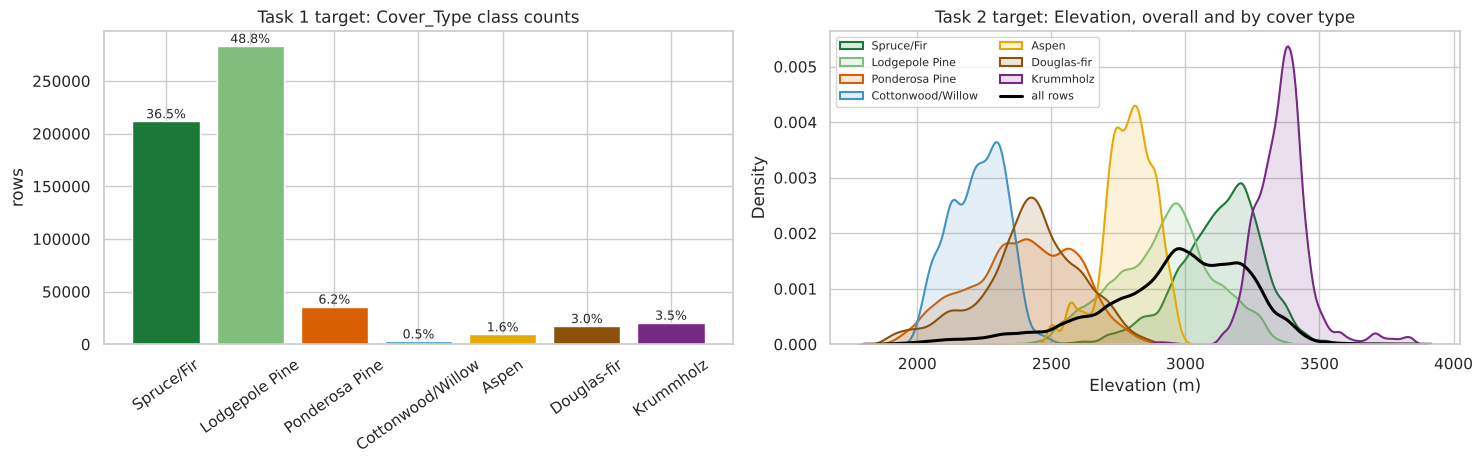

In [ ]:
class_counts = df['Cover_Type'].value_counts().sort_index()
class_table = pd.DataFrame({'class': class_counts.index.map(cover_type_names),
                            'rows': class_counts.values,
                            'percent': (100 * class_counts / len(df)).round(2).values},
                           index=class_counts.index)
display(class_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].bar(class_table['class'], class_table['rows'],
            color=[cover_type_colors[k] for k in class_table.index])
for i, (n, p) in enumerate(zip(class_table['rows'], class_table['percent'])):
    axes[0].text(i, n, f'{p:.1f}%', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Task 1 target: Cover_Type class counts')
axes[0].set_ylabel('rows')
axes[0].tick_params(axis='x', rotation=35)

for k, name in cover_type_names.items():
    sns.kdeplot(df.loc[df['Cover_Type'] == k, 'Elevation'], ax=axes[1], color=cover_type_colors[k],
                label=name, fill=True, alpha=0.15, linewidth=1.5, warn_singular=False)
sns.kdeplot(df['Elevation'], ax=axes[1], color='black', linewidth=2.2, label='all rows')
axes[1].set_title('Task 2 target: Elevation, overall and by cover type')
axes[1].set_xlabel('Elevation (m)')
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

The class imbalance is severe. Lodgepole Pine and Spruce/Fir together make up about 85% of the rows, while Cottonwood/Willow is under half a percent. This drives our metric choice in Section 3.1.

The right plot explains why the two tasks fit together. Each cover type lives in its own elevation band, with Krummholz highest and Cottonwood/Willow lowest. Elevation will be a strong input for classifying cover type, and in the regression task we find out how much of elevation the other features can recover without it.

<a id="sec-columns-we-drop-keep-or-create"></a>
#### Columns we drop, keep, or create

In [ ]:
MIN_SOIL_ROWS = 100
soil_counts = df[soil_cols].sum().sort_values()
rare_soils = soil_counts[soil_counts < MIN_SOIL_ROWS].index.tolist()
print('Five rarest soil types:')
print(soil_counts.head(5).to_string())
print('\nDropping (fewer than', MIN_SOIL_ROWS, 'rows):', rare_soils)

zero_3pm = df['Hillshade_3pm'] == 0
print(f'\nHillshade_3pm == 0 on {zero_3pm.sum():,} rows')
print('Aspect of those rows (degrees):', df.loc[zero_3pm, 'Aspect'].describe()[['min', '25%', '50%', '75%', 'max']].to_dict())
print('Slope of those rows:           ', df.loc[zero_3pm, 'Slope'].describe()[['min', '25%', '50%', '75%', 'max']].to_dict())
print('Median Slope of all rows:', df['Slope'].median())

Five rarest soil types:
Soil_Type15      3
Soil_Type7     105
Soil_Type36    119
Soil_Type8     179
Soil_Type37    298

Dropping (fewer than 100 rows): ['Soil_Type15']

Hillshade_3pm == 0 on 1,338 rows
Aspect of those rows (degrees): {'min': 1.0, '25%': 72.0, '50%': 86.0, '75%': 97.0, 'max': 356.0}
Slope of those rows:            {'min': 1.0, '25%': 31.0, '50%': 36.0, '75%': 40.0, 'max': 66.0}
Median Slope of all rows: 13.0


What we decided and why:

**Rare soil types.** `Soil_Type15` appears in only 3 of 581,012 rows. Our training sample has 50,000 rows, so the column would almost surely be all zeros there and can't teach any model anything. We drop it. The next rarest soil types have over 100 rows each, so we keep them, since a tree can still use a rare but real signal.

**`Hillshade_3pm` zeros.** At first these look like missing values. The check above says otherwise. The zero rows face north to east and sit on slopes much steeper than the median, so they really would be in full shadow at 3pm. We keep them as they are.

**`Aspect`.** Aspect is a compass bearing, so 359 degrees and 1 degree are almost the same direction even though the numbers are far apart. As we did in Lab One, we replace it with `aspect_sin` and `aspect_cos`, which put north, east, south and west on a circle with no break at 360. The raw `Aspect` column is dropped.

**`hydro_distance`.** The dataset gives the horizontal and vertical distance to water as separate columns. We add the straight line distance, the square root of the sum of their squares. Trees struggle to build this combination from two separate splits, so giving it directly can help.

**What we chose not to create.** In Lab One we decoded climatic and geologic zones from the soil type ELU codes in the dataset documentation. We leave them out here. Both zones are fixed functions of `Soil_Type`, which is already in the data, so they add no new information for classification. For the elevation task they would be worse than redundant, because the climatic zones are defined partly by altitude (montane, subalpine, alpine). That is close to giving the model the answer.

**Types.** The flag columns become `uint8` to save memory, and `Cover_Type` becomes `int8`.

In [ ]:
df = df.drop(columns=rare_soils)
soil_keep = [c for c in soil_cols if c not in rare_soils]

df['aspect_sin'] = np.sin(np.deg2rad(df['Aspect']))
df['aspect_cos'] = np.cos(np.deg2rad(df['Aspect']))
df['hydro_distance'] = np.hypot(df['Horizontal_Distance_To_Hydrology'], df['Vertical_Distance_To_Hydrology'])
df = df.drop(columns='Aspect')

df[wild_cols + soil_keep] = df[wild_cols + soil_keep].astype('uint8')
df['Cover_Type'] = df['Cover_Type'].astype('int8')

shared_cont = ['Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
               'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
               'Horizontal_Distance_To_Fire_Points', 'aspect_sin', 'aspect_cos', 'hydro_distance']
bin_cols = wild_cols + soil_keep

clf_cont = ['Elevation'] + shared_cont        # task 1 inputs
reg_cont = shared_cont                         # task 2 inputs: no Elevation (target) and no Cover_Type
clf_features = clf_cont + bin_cols
reg_features = reg_cont + bin_cols

print('classification inputs:', len(clf_features), '| regression inputs:', len(reg_features))

classification inputs: 55 | regression inputs: 54


**Scaling and dimensionality reduction.** Trees don't care about scale, because a split on `Elevation > 3000` works the same in meters or in standard deviations. So the decision tree, both forests, extra trees and the two boosting models get the raw values. KNN and elastic net are different. KNN measures distance, so without scaling `Horizontal_Distance_To_Roadways` (range 0 to 7,117) would drown out `Slope` (range 0 to 66). Elastic net penalizes coefficient size, so unscaled features would be penalized unevenly. For those two models we standardize the continuous columns and leave the 0/1 flags as they are.

The scaler lives inside a scikit-learn `Pipeline` (Raschka, 2015, ch. 6), so it is fit only on the training folds during cross validation and never sees the validation fold. Scaling the whole dataset first would leak test information into training.

We also tested PCA as a reduction step for KNN, since it is the one model where fewer dimensions could speed things up or help. That check is in Section 3.3 next to the KNN tuning, and the short answer is that it didn't help.

In [ ]:
def scaled(cont):
    # Standardize the continuous columns, pass the 0/1 flags through untouched
    return ColumnTransformer([('num', StandardScaler(), cont)], remainder='passthrough')

<a id="sec-2-2-the-final-dataset"></a>
### 2.2 The final dataset

In [ ]:
new_vars = {'aspect_sin': 'sine of Aspect (radians), east/west part of the compass bearing',
            'aspect_cos': 'cosine of Aspect (radians), north/south part of the compass bearing',
            'hydro_distance': 'straight line distance to nearest surface water (m)'}
rows = []
for c in clf_cont:
    rows.append({'feature': c, 'type': 'continuous (float)', 'scale': 'standardized for KNN / elastic net',
                 'classification input': 'yes', 'regression input': 'no (target)' if c == 'Elevation' else 'yes',
                 'new': 'yes' if c in new_vars else '', 'note': new_vars.get(c, '')})
rows.append({'feature': 'Wilderness_Area1 to Wilderness_Area4', 'type': 'binary 0/1 (one hot, 4 columns)',
             'scale': 'none', 'classification input': 'yes', 'regression input': 'yes', 'new': '',
             'note': 'one of four wilderness areas'})
rows.append({'feature': f'Soil_Type1 to Soil_Type40 ({len(soil_keep)} kept)', 'type': f'binary 0/1 (one hot, {len(soil_keep)} columns)',
             'scale': 'none', 'classification input': 'yes', 'regression input': 'yes', 'new': '',
             'note': 'dropped: ' + ', '.join(rare_soils)})
rows.append({'feature': 'Cover_Type', 'type': 'nominal int, 7 classes', 'scale': 'none',
             'classification input': 'TARGET', 'regression input': 'no (left out on purpose)', 'new': '', 'note': ''})
rows.append({'feature': 'Elevation (as target)', 'type': 'continuous (meters)', 'scale': 'none',
             'classification input': '', 'regression input': 'TARGET', 'new': '', 'note': ''})
display(pd.DataFrame(rows))
print(f'{len(df):,} rows | classification uses {len(clf_features)} inputs | regression uses {len(reg_features)} inputs')

,feature,type,scale,classification input,regression input,new,note
0,Elevation,continuous (float),standardized for KNN / elastic net,yes,no (target),,
1,Slope,continuous (float),standardized for KNN / elastic net,yes,yes,,
2,Horizontal_Distance_To_Hydrology,continuous (float),standardized for KNN / elastic net,yes,yes,,
3,Vertical_Distance_To_Hydrology,continuous (float),standardized for KNN / elastic net,yes,yes,,
4,Horizontal_Distance_To_Roadways,continuous (float),standardized for KNN / elastic net,yes,yes,,
5,Hillshade_9am,continuous (float),standardized for KNN / elastic net,yes,yes,,
6,Hillshade_Noon,continuous (float),standardized for KNN / elastic net,yes,yes,,
7,Hillshade_3pm,continuous (float),standardized for KNN / elastic net,yes,yes,,
8,Horizontal_Distance_To_Fire_Points,continuous (float),standardized for KNN / elastic net,yes,yes,,
9,aspect_sin,continuous (float),standardized for KNN / elastic net,yes,yes,yes,"sine of Aspect (radians), east/west part of th..."


581,012 rows | classification uses 55 inputs | regression uses 54 inputs


The final data has 581,012 rows. The classification task uses 55 inputs: 12 continuous ones (including the three new ones) and 43 binary flags (4 wilderness areas and 39 soil types). The regression task uses the same set minus `Elevation`, so 54 inputs. We kept every original column name exactly as UCI publishes it, and every new column has a lowercase name so it's easy to tell apart.

`Cover_Type` is not an input for the regression task. We went back and forth on this. Tree type and elevation are tightly linked, so including it would lower the error. But the point of the deployment story is to estimate or check elevation from map data, and cover type is not map data. It's an assigned label which may or may not be available in practice. So we leave it out.

<a id="sec-3-modeling-and-evaluation"></a>
## 3. Modeling and Evaluation

<a id="sec-3-1-evaluation-metrics"></a>
### 3.1 Evaluation metrics

**Classification: macro F1 is our main metric.** F1 for one class is the harmonic mean of its precision and recall. Macro F1 takes the plain average of the seven per class F1 scores, so Cottonwood/Willow counts exactly as much as Lodgepole Pine.

Why not accuracy? Because of the imbalance. Accuracy is dominated by the two big classes, so a model can ignore the five smaller cover types and still look good. The baselines below show this directly. Always guessing Lodgepole Pine gets close to 49% accuracy, while its macro F1 is about 0.09, which is what it actually deserves.

Why not weighted F1? It weights each class by its size, which brings the same problem back. And why F1 instead of just recall? For a forest map, both kinds of mistakes cost something. Missing a rare Cottonwood/Willow stand (low recall) hides a riparian habitat, and labeling a lot of other cells as Cottonwood/Willow (low precision) sends crews to the wrong places. F1 punishes both.

Alongside macro F1 we report accuracy (easy to explain to a non technical reader), balanced accuracy (the average of per class recall), and the full per class recall plus confusion matrices, since a single number can hide that one class is failing.

**Regression: RMSE is our main metric.** Root mean squared error is in meters, so "the model is off by about X meters on a typical cell" is easy to understand. Because errors are squared before averaging, RMSE punishes large misses more than small ones, and for a data quality check the large misses are important. We also report MAE, which is less sensitive to a few huge errors, and R², the share of elevation variance the model explains.

<a id="sec-3-2-splitting-the-data-into-training-and-testing"></a>
### 3.2 Splitting the data into training and testing

**What is realistic here?** In practice the Forest Service, for example, would label a limited number of cells through field surveys, which is expensive, and then use the model to predict the rest of the map. So a realistic setup trains on a small labeled sample and tests on a much larger area. We mirror that. We take a stratified random sample of **50,000 rows (about 8.6%) as our development set** and hold out the other **531,012 rows as the test set**. All tuning and model selection happens inside the 50,000 rows. The test set is touched once per model at the end. This uses as much testing data as we reasonably can while still giving every model enough rows to learn the rare classes. Even Cottonwood/Willow has over 200 rows in the development set.

There is another reason. KNN and the stacking model are slow to train and predict on hundreds of thousands of rows with 10 fold cross validation on the full data.

**Inside the development set** we use two levels:

1. **Grid search** runs on a stratified 15,000 row subset with 3 fold stratified cross validation. That's enough to rank hyperparameter settings and is cheap to run.
2. **The main evaluation** uses **stratified 10 fold cross validation** (Raschka, 2015, ch. 6) on all 50,000 development rows with the tuned settings. Stratification keeps every fold at the same class mix as the full data. Without it, a random fold could end up with very few Cottonwood/Willow rows, and its macro F1 would swing wildly from fold to fold. Ten folds gives ten paired scores per model, which is what the statistical tests in Section 3.5 need. For the regression task we use shuffled 10 fold cross validation, since there are no classes to stratify.

Since tuning and cross validation use the same development rows, the cross validation scores can be slightly optimistic. The large test set provides the unbiased evaluation, and Section 3.4 compares the two.

**Every model in a task gets exactly the same data.** All seven classifiers are tuned on the same 15,000 grid rows, cross validated on the same ten folds of the same 50,000 development rows, and tested on the same 531,012 rows. The three regressors share their own grid rows, folds and test rows in the same way, and they use the same development and test rows as the classifiers. Thus, the comparisons are fair. Any difference in scores comes from the models, not from one model getting an easier split. It's also what allows the paired tests in Section 3.5, which compare models fold by fold.

**One limitation.** Neighboring 30 meter cells are nearly identical, and a random split puts neighbors on both sides. That makes random split scores somewhat optimistic about how a model would do in a brand new region. The dataset has no coordinates, so we can't do a true spatial split. We note it here and come back to it in Deployment.

In [ ]:
idx_dev, idx_test = train_test_split(df.index, train_size=N_DEV, stratify=df['Cover_Type'],
                                     random_state=RANDOM_STATE)
idx_grid, _ = train_test_split(idx_dev, train_size=N_GRID, stratify=df.loc[idx_dev, 'Cover_Type'],
                               random_state=RANDOM_STATE)

X_dev_c, y_dev_c = df.loc[idx_dev, clf_features], df.loc[idx_dev, 'Cover_Type']
X_test_c, y_test_c = df.loc[idx_test, clf_features], df.loc[idx_test, 'Cover_Type']
X_grid_c, y_grid_c = df.loc[idx_grid, clf_features], df.loc[idx_grid, 'Cover_Type']

X_dev_r, y_dev_r = df.loc[idx_dev, reg_features], df.loc[idx_dev, 'Elevation']
X_test_r, y_test_r = df.loc[idx_test, reg_features], df.loc[idx_test, 'Elevation']
X_grid_r, y_grid_r = df.loc[idx_grid, reg_features], df.loc[idx_grid, 'Elevation']

skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
grid_cv_c = StratifiedKFold(n_splits=GRID_FOLDS, shuffle=True, random_state=RANDOM_STATE)
grid_cv_r = KFold(n_splits=GRID_FOLDS, shuffle=True, random_state=RANDOM_STATE)

mix = pd.DataFrame({name: 100 * s.value_counts(normalize=True).sort_index()
                    for name, s in [('full data', df['Cover_Type']), ('dev (50k)', y_dev_c),
                                    ('grid subset (15k)', y_grid_c), ('test', y_test_c)]}).round(2)
mix.index = mix.index.map(cover_type_names)
print(f'dev rows: {len(idx_dev):,} | grid rows: {len(idx_grid):,} | test rows: {len(idx_test):,}')
print('class mix (%):')
display(mix)

dev rows: 50,000 | grid rows: 15,000 | test rows: 531,012
class mix (%):


,full data,dev (50k),grid subset (15k),test
Cover_Type,,,,
Spruce/Fir,36.46,36.46,36.46,36.46
Lodgepole Pine,48.76,48.76,48.76,48.76
Ponderosa Pine,6.15,6.15,6.15,6.15
Cottonwood/Willow,0.47,0.47,0.47,0.47
Aspen,1.63,1.63,1.63,1.63
Douglas-fir,2.99,2.99,2.99,2.99
Krummholz,3.53,3.53,3.53,3.53


In [ ]:
# Check that every model sees the same rows: no overlap between development and test rows, both tasks share
# the same development and test rows, and the fold objects give identical folds every time they're called.
assert idx_dev.intersection(idx_test).empty
assert X_dev_r.index.equals(X_dev_c.index) and X_test_r.index.equals(X_test_c.index)
for cv, X, y in [(skf, X_dev_c, y_dev_c), (kf, X_dev_r, y_dev_r)]:
    first = [test for _, test in cv.split(X, y)]
    second = [test for _, test in cv.split(X, y)]
    assert all(np.array_equal(a, b) for a, b in zip(first, second))
fold_sizes = [len(test) for _, test in skf.split(X_dev_c, y_dev_c)]
print('All checks passed. Every model in a task is trained and scored on identical rows.')
print('Classification fold sizes:', fold_sizes)

All checks passed. Every model in a task is trained and scored on identical rows.
Classification fold sizes: [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


<a id="sec-baselines"></a>
#### Baselines

In [ ]:
def clf_metrics(y_true, y_pred):
    return {'macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'accuracy': accuracy_score(y_true, y_pred),
            'balanced accuracy': balanced_accuracy_score(y_true, y_pred),
            'weighted F1': f1_score(y_true, y_pred, average='weighted', zero_division=0)}

def reg_metrics(y_true, y_pred):
    return {'RMSE (m)': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE (m)': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}

baseline_c = {}
for strategy in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_dev_c, y_dev_c)
    baseline_c[f'Dummy ({strategy})'] = clf_metrics(y_test_c, dummy.predict(X_test_c))
dummy_r = DummyRegressor(strategy='mean').fit(X_dev_r, y_dev_r)
baseline_r = {'Dummy (predict mean)': reg_metrics(y_test_r, dummy_r.predict(X_test_r))}

display(pd.DataFrame(baseline_c).T.round(4))
display(pd.DataFrame(baseline_r).T.round(3))

,macro F1,accuracy,balanced accuracy,weighted F1
Dummy (most_frequent),0.0937,0.4876,0.1429,0.3196
Dummy (stratified),0.1426,0.3779,0.1426,0.3777


,RMSE (m),MAE (m),R2
Dummy (predict mean),279.984,216.794,-0.0


These are the numbers every model has to beat. Always guessing Lodgepole Pine scores 48.8% accuracy on the test set but a macro F1 of only 0.094, because it gets six of the seven classes completely wrong. Random guessing in proportion to the class sizes does no better at 0.143. That gap between accuracy and macro F1 is the whole argument for our metric choice.

For elevation, predicting the average for every cell is off by 280 m on a typical cell (RMSE), with an MAE of 217 m and an R² of zero by definition.

<a id="sec-3-3-building-and-tuning-the-models"></a>
### 3.3 Building and tuning the models

We tune every model with an exhaustive grid search (Raschka, 2015, ch. 6) on the 15,000 row subset, scored with our chosen metric (`f1_macro` for classification, negative RMSE for regression). All searches run in parallel across every CPU core with `n_jobs=-1`. The full search results are saved, because the Exceptional Work section analyzes them.

The seven classifiers:

- **Decision tree** (Breiman et al., 1984). One tree of yes/no splits. It's fast and easy to read, but a single deep tree tends to overfit. We tune depth, minimum leaf size and split criterion.
- **Random forest** (Breiman, 2001). Hundreds of deep trees, each grown on a bootstrap sample with a random subset of features at each split, then averaged. Averaging cancels out a lot of the overfitting. We tune the share of features tried at each split, the minimum leaf size and the maximum depth.
- **Weighted random forest** (Chen, Liaw & Breiman, 2004). The same model, but rare classes get larger sample weights so the trees pay more attention to them. `balanced_subsample` recomputes the weights inside each bootstrap sample. This is our direct response to the class imbalance.
- **KNN** (Cover & Hart, 1967). Labels a cell by a vote among the k most similar training cells. No training step, but predictions are slow on big data. We tune k, the distance metric (Manhattan or Euclidean) and whether closer neighbors get more weight.
- **Gradient boosting** (Friedman, 2001), using scikit-learn's histogram version, which is based on LightGBM (Ke et al., 2017). Trees are built one after another, each fixing the errors of the ones before. Early stopping on a 10% validation slice picks the number of trees. We tune the learning rate, tree size and minimum leaf size.
- **Extra trees** (Geurts, Ernst & Wehenkel, 2006). A random forest variant that picks each split threshold at random instead of searching for the best one, and gives every tree all of the training rows. Each tree is a bit weaker on its own, but the trees end up much more different from each other, so their average is often better. It also trains faster than a random forest. We tune the share of features tried at each split, the minimum leaf size and class weights.
- **LightGBM** (Ke et al., 2017). A popular gradient boosting library that grows each tree leaf by leaf instead of level by level. We tune the learning rate, the number of leaves per tree and the minimum number of rows per leaf. Like our histogram gradient boosting model, it decides when to stop adding trees by holding out 10% of its own training rows and stopping once the validation loss hasn't improved for 30 rounds, up to a cap of 3,000 trees.

**How we picked the last two.** We started with the first five. Then we screened four more candidates in a separate run, using the same grid rows, folds and test rows: extra trees, LightGBM, XGBoost (Chen & Guestrin, 2016) and CatBoost (Prokhorenkova et al., 2018). Extra trees and LightGBM were the only two that beat all five of our original models on the test set, so they joined the main comparison. XGBoost landed about level with our gradient boosting model. CatBoost came last, but a follow up check showed that was mostly because it needed far more than 3,000 boosting rounds at the learning rate it was tuned to, so we don't read much into its result.

Forests use 150 trees during the search to save time, then 300 in the final models.

**Speed.** The KNN classifier uses an exact k-d tree to find neighbors instead of comparing every pair of points. On this data it returns exactly the same neighbors about 2.7 times faster, which matters because KNN predictions are the slowest step in the notebook.

In [ ]:
# LightGBM with early stopping inside every fit, the same way HistGradientBoostingClassifier stops in this
# notebook: each fit holds out 10% of its own training rows and stops adding trees once the validation loss
# hasn't improved for 30 rounds. Only rows from the training fold are used, so nothing leaks. Each fit uses
# one thread with deterministic=True so the results repeat exactly. GridSearchCV and cross validation still
# use every core by running several fits at the same time.
class LGBMEarlyStop(ClassifierMixin, BaseEstimator):
    def __init__(self, learning_rate=0.1, num_leaves=31, min_child_samples=20, max_rounds=3000,
                 patience=30, random_state=RANDOM_STATE):
        self.learning_rate = learning_rate
        self.num_leaves = num_leaves
        self.min_child_samples = min_child_samples
        self.max_rounds = max_rounds
        self.patience = patience
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        self.classes_ = np.unique(y)
        y_enc = np.searchsorted(self.classes_, np.asarray(y))   # classes 1 to 7 become 0 to 6
        X_tr, X_val, y_tr, y_val = train_test_split(X, y_enc, test_size=0.1, stratify=y_enc,
                                                    random_state=self.random_state)
        self.model_ = lgb.LGBMClassifier(
            n_estimators=self.max_rounds, learning_rate=self.learning_rate, num_leaves=self.num_leaves,
            min_child_samples=self.min_child_samples, n_jobs=1, deterministic=True, force_col_wise=True,
            random_state=self.random_state, verbose=-1)
        self.model_.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
                        callbacks=[lgb.early_stopping(self.patience, verbose=False)])
        self.n_rounds_ = self.model_.best_iteration_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=np.float32))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [ ]:
grid_results, best_params, grid_times = {}, {}, {}

def tune(name, estimator, param_grid, X, y, cv, scoring):
    start = time.time()
    gs = GridSearchCV(estimator, param_grid, cv=cv, scoring=scoring, n_jobs=N_JOBS, refit=False)
    gs.fit(X, y)
    grid_times[name] = time.time() - start
    grid_results[name] = pd.DataFrame(gs.cv_results_)
    best_params[name] = gs.best_params_
    score = gs.best_score_ if scoring == 'f1_macro' else -gs.best_score_
    label = 'macro F1' if scoring == 'f1_macro' else 'RMSE'
    print(f'{name:<26} best {label} = {score:.4f}  ({len(grid_results[name])} settings, {grid_times[name]:.0f}s)')
    print(f'{"":<26} {gs.best_params_}')

clf_specs = {
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'max_depth': [5, 10, 15, 20, 25, None], 'min_samples_leaf': [1, 2, 5, 10, 25],
         'criterion': ['gini', 'entropy']}),
    'Random Forest': (
        RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
        {'max_features': ['sqrt', 0.3, 0.5], 'min_samples_leaf': [1, 2, 5], 'max_depth': [None, 25]}),
    'Weighted Random Forest': (
        RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
        {'class_weight': ['balanced', 'balanced_subsample'], 'max_features': ['sqrt', 0.3, 0.5],
         'min_samples_leaf': [1, 2, 5]}),
    'KNN': (
        Pipeline([('scale', scaled(clf_cont)), ('knn', KNeighborsClassifier(algorithm='kd_tree'))]),
        {'knn__n_neighbors': [1, 3, 5, 7, 9, 15, 25], 'knn__weights': ['uniform', 'distance'],
         'knn__p': [1, 2]}),
    'Gradient Boosting': (
        HistGradientBoostingClassifier(max_iter=300, early_stopping=True, validation_fraction=0.1,
                                       n_iter_no_change=15, random_state=RANDOM_STATE),
        {'learning_rate': [0.05, 0.1, 0.2], 'max_leaf_nodes': [15, 31, 63],
         'min_samples_leaf': [10, 20, 50]}),
    'Extra Trees': (
        ExtraTreesClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
        {'max_features': ['sqrt', 0.3, 0.5], 'min_samples_leaf': [1, 2, 5], 'class_weight': [None, 'balanced']}),
    'LightGBM': (
        LGBMEarlyStop(),
        {'learning_rate': [0.05, 0.1, 0.2], 'num_leaves': [31, 63, 127], 'min_child_samples': [10, 20]}),
}
clf_names = list(clf_specs)

Before tuning KNN, a quick check on PCA. We keep enough components to explain 95% of the variance and compare against no reduction, with everything else at default settings.

In [ ]:
pca_check = {}
for label, steps in [('no PCA', [('scale', scaled(clf_cont)), ('knn', KNeighborsClassifier())]),
                     ('PCA (95% variance)', [('scale', scaled(clf_cont)), ('pca', PCA(n_components=0.95, random_state=RANDOM_STATE)),
                                            ('knn', KNeighborsClassifier())])]:
    pipe = Pipeline(steps)
    scores = cross_val_score(pipe, X_grid_c, y_grid_c, cv=grid_cv_c, scoring='f1_macro', n_jobs=N_JOBS)
    n_comp = pipe.fit(X_grid_c, y_grid_c).named_steps['pca'].n_components_ if 'pca' in pipe.named_steps else len(clf_features)
    pca_check[label] = {'macro F1 (3 fold)': scores.mean(), 'dimensions': n_comp}
pd.DataFrame(pca_check).T

,macro F1 (3 fold),dimensions
no PCA,0.591219,55.0
PCA (95% variance),0.539899,13.0


PCA hurts. Keeping 95% of the variance cuts the inputs from 55 to 13 dimensions, but macro F1 drops from 0.591 to 0.540. PCA keeps the directions with the most variance, and most of that variance comes from the large continuous columns like the road and fire point distances. The soil and wilderness flags have small variance, so they mostly get left out, yet they carry a lot of class information. High variance is not the same thing as useful for prediction. We don't use PCA anywhere else.

In [ ]:
for name, (estimator, grid) in clf_specs.items():
    tune(name, estimator, grid, X_grid_c, y_grid_c, grid_cv_c, 'f1_macro')

Decision Tree              best macro F1 = 0.6101  (60 settings, 10s)
                           {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2}


Random Forest              best macro F1 = 0.6982  (18 settings, 112s)
                           {'max_depth': 25, 'max_features': 0.5, 'min_samples_leaf': 1}


Weighted Random Forest     best macro F1 = 0.7046  (18 settings, 95s)
                           {'class_weight': 'balanced', 'max_features': 'sqrt', 'min_samples_leaf': 1}


KNN                        best macro F1 = 0.6492  (28 settings, 61s)
                           {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}


Gradient Boosting          best macro F1 = 0.7033  (27 settings, 108s)
                           {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


Extra Trees                best macro F1 = 0.7414  (18 settings, 60s)
                           {'class_weight': None, 'max_features': 0.5, 'min_samples_leaf': 1}


LightGBM                   best macro F1 = 0.7047  (18 settings, 41s)
                           {'learning_rate': 0.05, 'min_child_samples': 20, 'num_leaves': 127}


The regression models:

- **Random forest regressor.** The same forest idea, averaging the numeric predictions of many trees. We tune the share of features per split and the minimum leaf size.
- **KNN regressor.** Predicts the (optionally distance weighted) average elevation of the k most similar cells. Same scaling pipeline and same tuning knobs as the classifier.
- **Multiple linear regression with an elastic net penalty** (Zou & Hastie, 2005). A linear model whose loss function adds a mix of an L1 penalty (which pushes useless coefficients to exactly zero) and an L2 penalty (which shrinks correlated coefficients together). `alpha` sets the overall penalty strength and `l1_ratio` sets the mix. The L2 part matters here, because each one hot group sums to 1 in every row, which is perfectly collinear with the intercept. Plain least squares can't give stable coefficients in that case, and the penalty fixes it. We set `precompute=True`, which computes the 54 x 54 Gram matrix once instead of passing over all the rows on every update. It reaches the same solution (our check matched the scores to 11 decimal places) about 80 times faster.

In [ ]:
reg_specs = {
    'Random Forest Regressor': (
        RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
        {'max_features': [0.3, 0.5, 1.0], 'min_samples_leaf': [1, 2, 5]}),
    'KNN Regressor': (
        Pipeline([('scale', scaled(reg_cont)), ('knn', KNeighborsRegressor())]),
        {'knn__n_neighbors': [3, 5, 7, 9, 15, 25], 'knn__weights': ['uniform', 'distance'], 'knn__p': [1, 2]}),
    'Elastic Net': (
        Pipeline([('scale', scaled(reg_cont)), ('enet', ElasticNet(max_iter=20000, precompute=True, random_state=RANDOM_STATE))]),
        {'enet__alpha': np.logspace(-4, 1, 11), 'enet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]}),
}
reg_names = list(reg_specs)

for name, (estimator, grid) in reg_specs.items():
    tune(name, estimator, grid, X_grid_r, y_grid_r, grid_cv_r, 'neg_root_mean_squared_error')

Random Forest Regressor    best RMSE = 100.0337  (9 settings, 110s)
                           {'max_features': 1.0, 'min_samples_leaf': 1}


KNN Regressor              best RMSE = 120.6661  (24 settings, 27s)
                           {'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'distance'}


Elastic Net                best RMSE = 130.8130  (66 settings, 3s)
                           {'enet__alpha': np.float64(0.0001), 'enet__l1_ratio': 0.9}


A few of the chosen settings say something about the data:

- **KNN picked k = 3 with distance weighting**, for both tasks. A very small k means the best evidence for a cell is its handful of closest look alikes. That fits what we know about the data, since neighboring 30 meter cells are almost identical.
- **The decision tree picked no depth limit.** It wanted to grow as deep as possible, with a minimum leaf of 2 to stop the very last splits. That's a sign the class boundaries are detailed, and it's why a single tree overfits while forests do well.
- **The two forests chose differently.** The plain random forest wanted half of the features at each split. The weighted forest preferred the square root (about 7 features), which makes its trees more varied and noticeably faster to train.
- **Extra trees picked half of the features at each split, a leaf size of 1 and no class weights.** Like the plain random forest, it wants as much local detail as it can get. Class weights didn't improve its macro F1.
- **LightGBM picked the slowest learning rate (0.05) and the largest trees (127 leaves).** With early stopping deciding the number of trees, a slow learning rate with many small corrections did better than a few big ones.
- **The random forest regressor picked `max_features = 1.0`**, meaning every split looks at every feature. At that point it's plain bagging of regression trees.
- **The elastic net picked the smallest alpha in the grid (0.0001)** with `l1_ratio = 0.9`. In other words it wants almost no penalty at all. We come back to why in Section 3.4.

All grid scores are lower than the final cross validation scores below, because the grid search trains on only 10,000 rows per fold instead of 45,000. The ranking of settings is what we need from the search, not its absolute scores.

In [ ]:
def build_model(name):
    # Rebuild a model with its tuned settings; final forests get more trees and every core
    specs = clf_specs if name in clf_specs else reg_specs
    model = clone(specs[name][0]).set_params(**best_params[name])
    if isinstance(model, (RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier)):
        model.set_params(n_estimators=N_TREES, n_jobs=N_JOBS)
    if isinstance(model, Pipeline) and 'knn' in model.named_steps:
        model.set_params(knn__n_jobs=N_JOBS)
    return model

final_params = pd.DataFrame([{'model': n, 'tuned settings': best_params[n]} for n in clf_names + reg_names])
final_params

,model,tuned settings
0,Decision Tree,"{'criterion': 'entropy', 'max_depth': None, 'm..."
1,Random Forest,"{'max_depth': 25, 'max_features': 0.5, 'min_sa..."
2,Weighted Random Forest,"{'class_weight': 'balanced', 'max_features': '..."
3,KNN,"{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__wei..."
4,Gradient Boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 63, ..."
5,Extra Trees,"{'class_weight': None, 'max_features': 0.5, 'm..."
6,LightGBM,"{'learning_rate': 0.05, 'min_child_samples': 2..."
7,Random Forest Regressor,"{'max_features': 1.0, 'min_samples_leaf': 1}"
8,KNN Regressor,"{'knn__n_neighbors': 3, 'knn__p': 2, 'knn__wei..."
9,Elastic Net,"{'enet__alpha': 0.0001, 'enet__l1_ratio': 0.9}"


<a id="sec-3-4-results"></a>
### 3.4 Results

**Step 1: stratified 10 fold cross validation** of each tuned model on the 50,000 development rows. We keep every fold's score, not only the average, because the spread across folds and the paired fold scores both get used later.

In [ ]:
cv_clf = {}
for name in clf_names:
    start = time.time()
    jobs = N_JOBS if name == 'LightGBM' else 1   # LightGBM runs one thread per fit, so run folds side by side
    cv_clf[name] = cross_validate(build_model(name), X_dev_c, y_dev_c, cv=skf, n_jobs=jobs,
                                  scoring=['f1_macro', 'accuracy', 'balanced_accuracy'])
    print(f'{name:<24} macro F1 {cv_clf[name]["test_f1_macro"].mean():.4f} '
          f'+/- {cv_clf[name]["test_f1_macro"].std():.4f}   ({time.time() - start:.0f}s)')

cv_reg = {}
reg_scoring = ['neg_root_mean_squared_error', 'neg_mean_absolute_error', 'r2']
for name in reg_names:
    start = time.time()
    cv_reg[name] = cross_validate(build_model(name), X_dev_r, y_dev_r, cv=kf, n_jobs=1, scoring=reg_scoring)
    print(f'{name:<24} RMSE {-cv_reg[name]["test_neg_root_mean_squared_error"].mean():.2f} m '
          f'+/- {cv_reg[name]["test_neg_root_mean_squared_error"].std():.2f}   ({time.time() - start:.0f}s)')

# Plain least squares as a reference point for the elastic net (not one of our three models)
ols = Pipeline([('scale', scaled(reg_cont)), ('ols', LinearRegression())])
ols_cv = cross_validate(ols, X_dev_r, y_dev_r, cv=kf, scoring=reg_scoring)
print(f'{"(reference) plain OLS":<24} RMSE {-ols_cv["test_neg_root_mean_squared_error"].mean():.2f} m')

Decision Tree            macro F1 0.7489 +/- 0.0095   (7s)


Random Forest            macro F1 0.8305 +/- 0.0180   (309s)


Weighted Random Forest   macro F1 0.8131 +/- 0.0099   (73s)


KNN                      macro F1 0.7563 +/- 0.0149   (14s)


Gradient Boosting        macro F1 0.8370 +/- 0.0108   (233s)


Extra Trees              macro F1 0.8552 +/- 0.0134   (151s)


LightGBM                 macro F1 0.8430 +/- 0.0108   (69s)


Random Forest Regressor  RMSE 74.02 m +/- 1.06   (705s)


KNN Regressor            RMSE 92.43 m +/- 1.48   (5s)


Elastic Net              RMSE 130.37 m +/- 0.98   (1s)


(reference) plain OLS    RMSE 130.37 m


In [ ]:
def summarize_cv(cv, cols, flip=()):
    out = {}
    for name, res in cv.items():
        row = {}
        for key, label in cols.items():
            vals = -res[key] if key in flip else res[key]
            row[label] = f'{vals.mean():.4f} +/- {vals.std():.4f}'
        row['fit time per fold (s)'] = round(res['fit_time'].mean(), 1)
        out[name] = row
    return pd.DataFrame(out).T

display(summarize_cv(cv_clf, {'test_f1_macro': 'macro F1', 'test_accuracy': 'accuracy',
                              'test_balanced_accuracy': 'balanced accuracy'}))
display(summarize_cv(cv_reg, {'test_neg_root_mean_squared_error': 'RMSE (m)',
                              'test_neg_mean_absolute_error': 'MAE (m)', 'test_r2': 'R2'},
                     flip=('test_neg_root_mean_squared_error', 'test_neg_mean_absolute_error')))

,macro F1,accuracy,balanced accuracy,fit time per fold (s)
Decision Tree,0.7489 +/- 0.0095,0.8228 +/- 0.0053,0.7327 +/- 0.0094,0.6
Random Forest,0.8305 +/- 0.0180,0.8883 +/- 0.0036,0.7936 +/- 0.0183,30.6
Weighted Random Forest,0.8131 +/- 0.0099,0.8575 +/- 0.0038,0.8244 +/- 0.0080,7.1
KNN,0.7563 +/- 0.0149,0.8411 +/- 0.0059,0.7415 +/- 0.0144,0.3
Gradient Boosting,0.8370 +/- 0.0108,0.8816 +/- 0.0039,0.8026 +/- 0.0118,23.1
Extra Trees,0.8552 +/- 0.0134,0.9031 +/- 0.0041,0.8288 +/- 0.0133,14.8
LightGBM,0.8430 +/- 0.0108,0.8914 +/- 0.0049,0.8070 +/- 0.0124,11.9


,RMSE (m),MAE (m),R2,fit time per fold (s)
Random Forest Regressor,74.0231 +/- 1.0566,49.3244 +/- 0.4683,0.9301 +/- 0.0016,70.0
KNN Regressor,92.4274 +/- 1.4761,57.2419 +/- 0.7198,0.8909 +/- 0.0037,0.0
Elastic Net,130.3709 +/- 0.9824,104.1831 +/- 0.8844,0.7830 +/- 0.0063,0.1


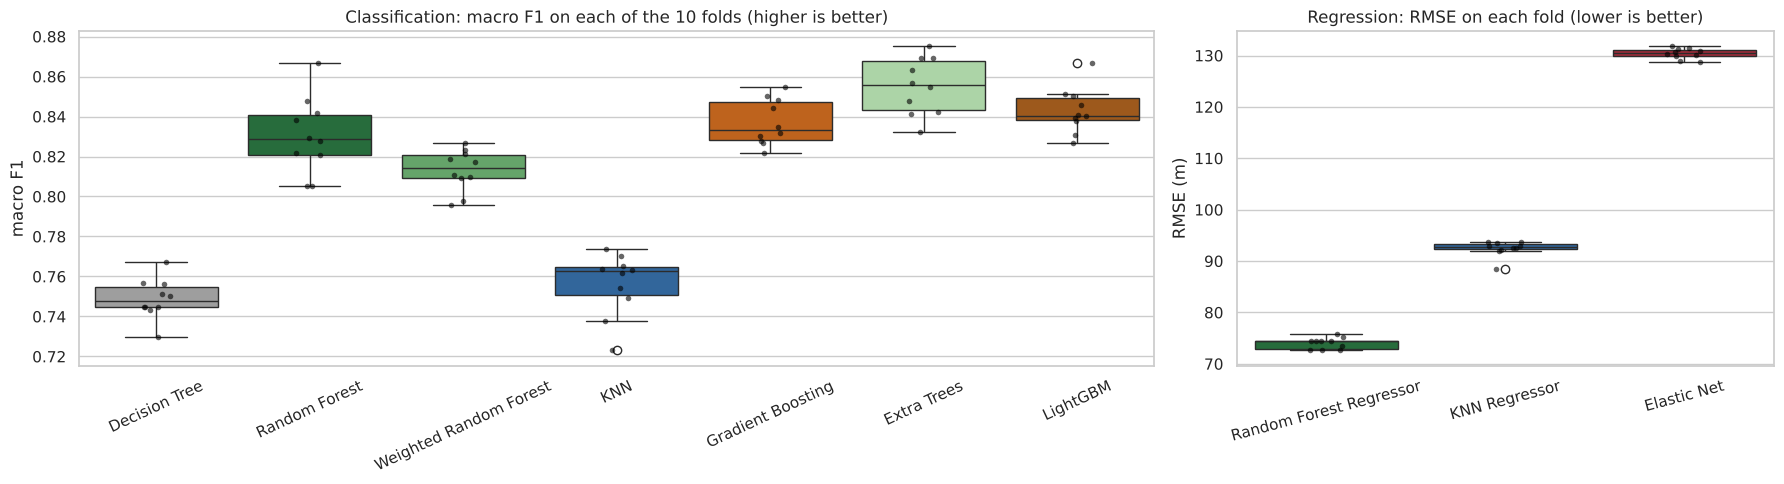

In [ ]:
model_colors = {'Decision Tree': '#9e9e9e', 'Random Forest': '#1b7837', 'Weighted Random Forest': '#5aae61',
                'KNN': '#2166ac', 'Gradient Boosting': '#d95f02', 'Extra Trees': '#a6dba0', 'LightGBM': '#b35806',
                'Stacking': '#762a83',
                'Random Forest Regressor': '#1b7837', 'KNN Regressor': '#2166ac', 'Elastic Net': '#b2182b'}

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})
f1_folds = pd.DataFrame({n: cv_clf[n]['test_f1_macro'] for n in clf_names})
sns.boxplot(data=f1_folds, ax=axes[0], palette=[model_colors[n] for n in clf_names])
sns.stripplot(data=f1_folds, ax=axes[0], color='black', size=4, alpha=0.6)
axes[0].set_title('Classification: macro F1 on each of the 10 folds (higher is better)')
axes[0].set_ylabel('macro F1')
axes[0].tick_params(axis='x', rotation=25)

rmse_folds = pd.DataFrame({n: -cv_reg[n]['test_neg_root_mean_squared_error'] for n in reg_names})
sns.boxplot(data=rmse_folds, ax=axes[1], palette=[model_colors[n] for n in reg_names])
sns.stripplot(data=rmse_folds, ax=axes[1], color='black', size=4, alpha=0.6)
axes[1].set_title('Regression: RMSE on each fold (lower is better)')
axes[1].set_ylabel('RMSE (m)')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Classification.** Extra trees has the highest mean macro F1 (0.855), followed by LightGBM (0.843), gradient boosting (0.837) and the random forest (0.831), then the weighted random forest (0.813). KNN (0.756) and the single decision tree (0.749) are clearly a tier below. The fold to fold spread is small for every model, about 0.01 to 0.02, so these averages are stable.

The secondary metrics provide some interesting observations. Extra trees also leads on accuracy (0.903) and on balanced accuracy (0.829), so its lead isn't an artifact of the metric we picked. Among the original five, the plain random forest has the best accuracy (0.888), so it's strong on the big classes, and the weighted random forest has the best balanced accuracy (0.824), so it's strong at finding the small ones. The weighted forest gives up some macro F1 because the weighting pulls in extra false positives for the rare classes, which lowers their precision. The eventual choice could depend on which cover type is more important for the use case.

**Regression.** The random forest regressor is far ahead, at 74.0 m RMSE and an R² of 0.930. KNN comes in at 92.4 m and the elastic net at 130.4 m. All three beat the 280 m baseline by a wide margin. The elastic net scores exactly the same as plain least squares (130.37 m), which matches its near zero tuned penalty. With 50,000 rows and only 54 inputs, a linear model isn't overfitting, so a penalty has nothing to fix. Its problem is bias. Elevation doesn't move in straight lines with these inputs, so there is some nonlinearity at play.

**Step 2: the held out test set.** Each tuned model is now fit once on all 50,000 development rows and scored on the 531,012 test rows it has never seen.

In [ ]:
fitted, test_pred, timing = {}, {}, {}
for name in clf_names + reg_names:
    is_clf = name in clf_specs
    X_tr, y_tr, X_te = (X_dev_c, y_dev_c, X_test_c) if is_clf else (X_dev_r, y_dev_r, X_test_r)
    model = build_model(name)
    t0 = time.time(); model.fit(X_tr, y_tr); t1 = time.time()
    test_pred[name] = model.predict(X_te); t2 = time.time()
    fitted[name] = model
    timing[name] = {'fit (s)': round(t1 - t0, 1), 'predict 531k rows (s)': round(t2 - t1, 1)}

test_clf = pd.DataFrame({n: clf_metrics(y_test_c, test_pred[n]) for n in clf_names}).T
test_clf['mean CV macro F1'] = [cv_clf[n]['test_f1_macro'].mean() for n in clf_names]
test_clf = test_clf.join(pd.DataFrame(timing).T)
display(pd.concat([pd.DataFrame(baseline_c).T, test_clf]).round(4))

test_reg = pd.DataFrame({n: reg_metrics(y_test_r, test_pred[n]) for n in reg_names}).T
test_reg['mean CV RMSE (m)'] = [-cv_reg[n]['test_neg_root_mean_squared_error'].mean() for n in reg_names]
test_reg = test_reg.join(pd.DataFrame(timing).T)
display(pd.concat([pd.DataFrame(baseline_r).T, test_reg]).round(3))

,macro F1,accuracy,balanced accuracy,weighted F1,mean CV macro F1,fit (s),predict 531k rows (s)
Dummy (most_frequent),0.0937,0.4876,0.1429,0.3196,NaN,NaN,NaN
Dummy (stratified),0.1426,0.3779,0.1426,0.3777,NaN,NaN,NaN
Decision Tree,0.7529,0.8300,0.7422,0.8297,0.7489,0.7,0.3
Random Forest,0.8320,0.8939,0.7977,0.8925,0.8305,32.7,12.4
Weighted Random Forest,0.8171,0.8636,0.8304,0.8639,0.8131,8.0,14.7
KNN,0.7636,0.8484,0.7511,0.8480,0.7563,0.5,128.8
Gradient Boosting,0.8365,0.8863,0.8079,0.8854,0.8370,24.3,25.9
Extra Trees,0.8564,0.9081,0.8316,0.9074,0.8552,15.8,19.4
LightGBM,0.8453,0.8998,0.8147,0.8989,0.8430,13.4,155.5


,RMSE (m),MAE (m),R2,mean CV RMSE (m),fit (s),predict 531k rows (s)
Dummy (predict mean),279.984,216.794,-0.000,NaN,NaN,NaN
Random Forest Regressor,73.148,48.308,0.932,74.023,79.6,24.3
KNN Regressor,91.336,56.108,0.894,92.427,0.0,52.7
Elastic Net,130.579,104.286,0.782,130.371,0.1,0.1


The test scores match the cross validation scores closely. Every classifier's test macro F1 is within 0.01 of its cross validated mean, and every regressor's test RMSE is within about 1 m. So the optimism we were concerned about earlier, from tuning and evaluating on the same development rows, turned out to be negligible.

On the 531,012 unseen rows, extra trees is the best classifier on every overall metric: macro F1 0.856, accuracy 90.8% and balanced accuracy 0.832. LightGBM is second on macro F1 (0.845). Among the original five, gradient boosting has the best macro F1 (0.837), the random forest the best accuracy (89.4%) and the weighted random forest the best balanced accuracy (0.830). The random forest regressor predicts elevation within 73.1 m RMSE and 48.3 m MAE, which cuts the baseline error by about 74%.

The timing columns matter for deployment. KNN needs no training, but predicting the test set took about 44 seconds on our 24 core machine, even with the faster k-d tree search, compared to 2 seconds for the random forest and 6 seconds for gradient boosting. KNN has to compare every new cell to all 50,000 training cells. On a map with millions of cells that becomes a real cost. LightGBM is also slow to predict in our setup, because we run each LightGBM fit on a single thread to keep its results exactly repeatable, so it can't use the extra cores. In a real deployment it would use all of them. Extra trees trains in about half the time of the random forest and predicts in a similar time.

<a id="sec-where-the-classifiers-make-mistakes"></a>
#### Where the classifiers make mistakes

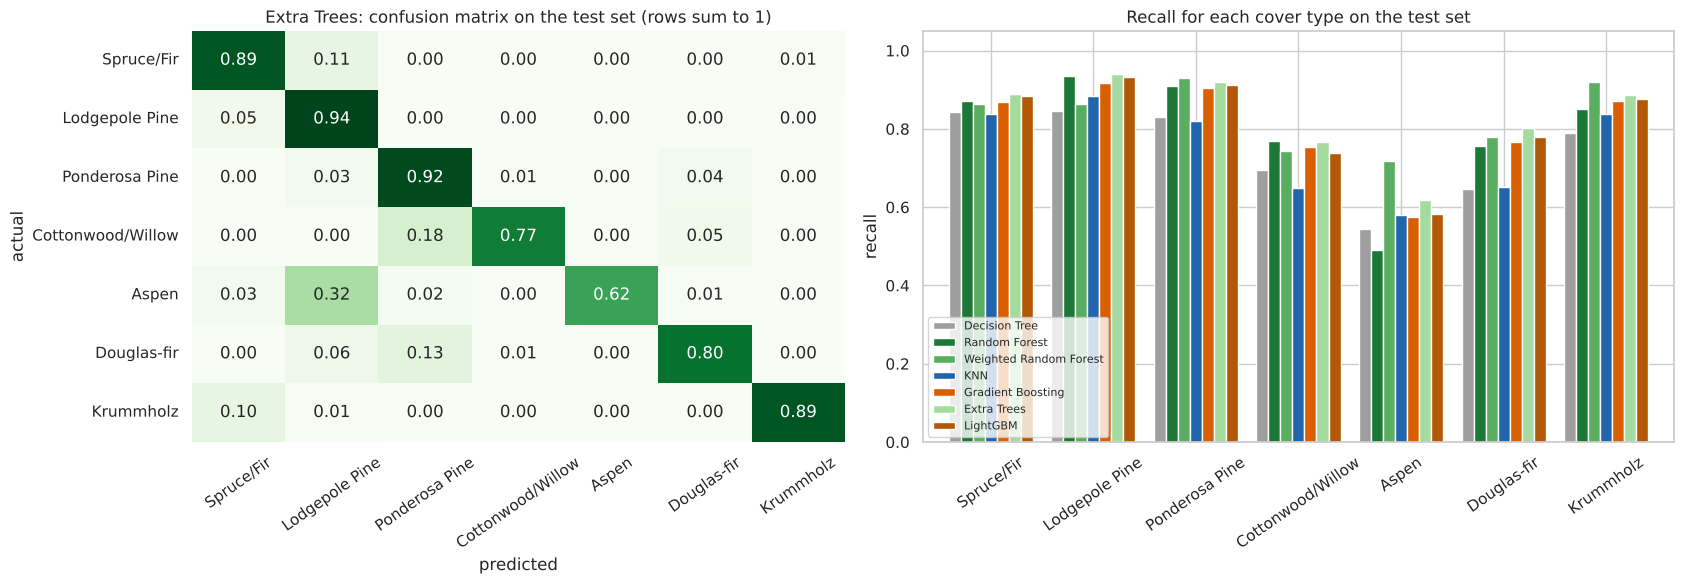

,Decision Tree,Random Forest,Weighted Random Forest,KNN,Gradient Boosting,Extra Trees,LightGBM
Spruce/Fir,0.842,0.872,0.863,0.838,0.867,0.889,0.883
Lodgepole Pine,0.846,0.934,0.863,0.884,0.918,0.940,0.932
Ponderosa Pine,0.829,0.910,0.930,0.819,0.905,0.919,0.911
Cottonwood/Willow,0.696,0.770,0.742,0.649,0.753,0.766,0.738
Aspen,0.545,0.491,0.717,0.580,0.574,0.619,0.583
Douglas-fir,0.647,0.756,0.779,0.651,0.766,0.802,0.779
Krummholz,0.790,0.851,0.919,0.837,0.872,0.887,0.877


In [ ]:
best_clf = test_clf['macro F1'].idxmax()

cm = confusion_matrix(y_test_c, test_pred[best_clf], labels=list(cover_type_names))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1, 1.15]})
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', ax=axes[0], cbar=False,
            xticklabels=class_labels, yticklabels=class_labels)
axes[0].set_title(f'{best_clf}: confusion matrix on the test set (rows sum to 1)')
axes[0].set_xlabel('predicted'); axes[0].set_ylabel('actual')
axes[0].tick_params(axis='x', rotation=35)

recall_tbl = pd.DataFrame({n: recall_score(y_test_c, test_pred[n], average=None, labels=list(cover_type_names))
                           for n in clf_names}, index=class_labels)
recall_tbl.plot.bar(ax=axes[1], color=[model_colors[n] for n in clf_names], width=0.82)
axes[1].set_title('Recall for each cover type on the test set')
axes[1].set_ylabel('recall'); axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=35)
axes[1].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()
display(recall_tbl.round(3))

The confusion matrix for extra trees (our best model on macro F1) shows that the mistakes are not random. They follow the elevation bands from Section 2.1:

- **Aspen is the hardest class.** Only 62% of Aspen cells are found, and 32% are called Lodgepole Pine. The two share the same middle elevations, and Aspen often grows in patches inside lodgepole forest.
- **Cottonwood/Willow and Douglas-fir get confused with Ponderosa Pine** (18% and 13% of their cells). All three live in the low elevation part of the forest, largely in Wilderness_Area4.
- **Krummholz gets confused with Spruce/Fir** (10%), its neighbor just below the treeline.
- **Spruce/Fir and Lodgepole Pine** trade 5% to 11% of their cells. Their elevation ranges overlap heavily, and they make up 85% of the data, so these small rates add up to most of the raw errors.

The other strong models make the same kinds of mistakes, just more often, so the pattern comes from the data and not from one model.

The recall chart compares all seven models class by class. Extra trees has the best recall of any model on Spruce/Fir, Lodgepole Pine and Douglas-fir, and it improves on Aspen compared to the plain random forest (62% vs 49%). The weighted random forest is still the standout for the rare classes. It finds 72% of Aspen cells, plus the best recall on Ponderosa Pine and Krummholz. It pays for this on Lodgepole Pine (86% vs 93% for the plain random forest). For someone using the map to locate aspen stands, which matter for wildlife habitat, the weighted forest is the more useful model even though its macro F1 is lower.

<a id="sec-a-closer-look-at-the-two-random-forests"></a>
#### A closer look at the two random forests

Moinak's notebook (Ghosh, 2026) went further on the two forests than the recall chart above, with full classification reports and a breakdown of the Aspen mistakes by wilderness area. We bring both checks in here, applied to our tuned models and our test set.

In [ ]:
# Per class precision, recall and F1 for the two forests.
# Adapted from Moinak Ghosh's random forest notebook (Group 3), which reported both forests this way.
from sklearn.metrics import classification_report

forest_pair = ['Random Forest', 'Weighted Random Forest']
for name in forest_pair:
    print(f'{name} (test set, {len(y_test_c):,} rows)')
    print(classification_report(y_test_c, test_pred[name], labels=list(cover_type_names),
                                target_names=class_labels, digits=3, zero_division=0))

Random Forest (test set, 531,012 rows)
                   precision    recall  f1-score   support

       Spruce/Fir      0.905     0.872     0.889    193610
   Lodgepole Pine      0.887     0.934     0.910    258921
   Ponderosa Pine      0.884     0.910     0.897     32677
Cottonwood/Willow      0.829     0.770     0.798      2511
            Aspen      0.890     0.491     0.633      8676
      Douglas-fir      0.858     0.756     0.804     15872
        Krummholz      0.942     0.851     0.894     18745

         accuracy                          0.894    531012
        macro avg      0.885     0.798     0.832    531012
     weighted avg      0.894     0.894     0.893    531012

Weighted Random Forest (test set, 531,012 rows)


                   precision    recall  f1-score   support

       Spruce/Fir      0.857     0.863     0.860    193610
   Lodgepole Pine      0.895     0.863     0.879    258921
   Ponderosa Pine      0.800     0.930     0.860     32677
Cottonwood/Willow      0.816     0.742     0.777      2511
            Aspen      0.702     0.717     0.709      8676
      Douglas-fir      0.715     0.779     0.746     15872
        Krummholz      0.860     0.919     0.888     18745

         accuracy                          0.864    531012
        macro avg      0.806     0.830     0.817    531012
     weighted avg      0.865     0.864     0.864    531012



In [ ]:
# Where do the Aspen mistakes go, and in which wilderness area?
# Adapted from Moinak Ghosh's notebook (Group 3): Aspen false positives and false negatives, then the
# Aspen / Lodgepole Pine error rates split by wilderness area. Area names come from the UCI documentation.
area_names = {'Wilderness_Area1': 'Rawah', 'Wilderness_Area2': 'Neota',
              'Wilderness_Area3': 'Comanche Peak', 'Wilderness_Area4': 'Cache la Poudre'}
ASPEN, LODGEPOLE = 5, 2
test_area = df.loc[idx_test, wild_cols].idxmax(axis=1)

fp, fn = {}, {}
for name in forest_pair:
    pred = pd.Series(test_pred[name], index=y_test_c.index)
    fp[name] = y_test_c[(pred == ASPEN) & (y_test_c != ASPEN)].map(cover_type_names).value_counts()
    fn[name] = pred[(y_test_c == ASPEN) & (pred != ASPEN)].map(cover_type_names).value_counts()
print('Other cover types predicted as Aspen (false positives):')
display(pd.DataFrame(fp).fillna(0).astype(int).sort_values('Weighted Random Forest', ascending=False))
print('Actual Aspen predicted as something else (false negatives):')
display(pd.DataFrame(fn).fillna(0).astype(int).sort_values('Weighted Random Forest', ascending=False))

rows = []
for area in wild_cols:
    in_area = (test_area == area).to_numpy()
    for actual, predicted in [(ASPEN, LODGEPOLE), (LODGEPOLE, ASPEN)]:
        is_actual = in_area & (y_test_c.to_numpy() == actual)
        row = {'wilderness area': f'{area} ({area_names[area]})',
               'actual': cover_type_names[actual], 'predicted as': cover_type_names[predicted],
               'actual rows': int(is_actual.sum())}
        for name in forest_pair:
            errors = int((is_actual & (test_pred[name] == predicted)).sum())
            row[f'{name} error rate (%)'] = 100 * errors / is_actual.sum() if is_actual.sum() else np.nan
        rows.append(row)
display(pd.DataFrame(rows).round(2))

Other cover types predicted as Aspen (false positives):


,Random Forest,Weighted Random Forest
Cover_Type,,
Lodgepole Pine,450,2229
Spruce/Fir,48,360
Ponderosa Pine,19,34
Douglas-fir,9,14
Krummholz,0,2


Actual Aspen predicted as something else (false negatives):


,Random Forest,Weighted Random Forest
Lodgepole Pine,4031,1999
Ponderosa Pine,164,217
Spruce/Fir,187,155
Douglas-fir,36,86


,wilderness area,actual,predicted as,actual rows,Random Forest error rate (%),Weighted Random Forest error rate (%)
0,Wilderness_Area1 (Rawah),Aspen,Lodgepole Pine,3450,36.14,23.19
1,Wilderness_Area1 (Rawah),Lodgepole Pine,Aspen,133535,0.17,0.59
2,Wilderness_Area2 (Neota),Aspen,Lodgepole Pine,0,NaN,NaN
3,Wilderness_Area2 (Neota),Lodgepole Pine,Aspen,8190,0.00,0.00
4,Wilderness_Area3 (Comanche Peak),Aspen,Lodgepole Pine,5226,53.27,22.94
5,Wilderness_Area3 (Comanche Peak),Lodgepole Pine,Aspen,114447,0.19,1.26
6,Wilderness_Area4 (Cache la Poudre),Aspen,Lodgepole Pine,0,NaN,NaN
7,Wilderness_Area4 (Cache la Poudre),Lodgepole Pine,Aspen,2749,0.00,0.00


The classification reports show exactly how class weighting changes the forest. The plain random forest is careful about predicting rare classes. When it calls a cell Aspen it's right 89% of the time, but it only finds 49% of the real Aspen cells. The weighted forest flips that tradeoff. Its Aspen precision drops to 70% while recall rises to 72%. The same pattern shows up for Ponderosa Pine, Douglas-fir and Krummholz. Averaged over the seven classes, the plain forest has higher precision (0.885 vs 0.806) and the weighted forest has higher recall (0.830 vs 0.798). Macro F1 balances the two, and the plain forest comes out a little ahead.

The Aspen breakdown, following Moinak's analysis, shows that almost every Aspen mistake involves Lodgepole Pine. The plain forest calls 4,031 real Aspen cells Lodgepole Pine, which is 46% of all Aspen in the test set. The weighted forest cuts that to 1,999, but in exchange it calls 2,229 Lodgepole Pine cells Aspen, compared to 450 for the plain forest.

Splitting by wilderness area shows where this happens. Aspen only grows in Rawah and Comanche Peak in this data. The plain forest mislabels Aspen as Lodgepole Pine 53% of the time in Comanche Peak and 36% of the time in Rawah. The weighted forest brings both down to about 23%. The reverse error stays tiny in every area (under 1.3%), simply because there are so many more Lodgepole Pine cells. Moinak found the same two areas were the problem in his validation data. For a land manager looking for aspen stands in Comanche Peak, the weighted forest is clearly the better tool, even though its overall macro F1 is lower.

<a id="sec-how-the-regression-models-miss"></a>
#### How the regression models miss

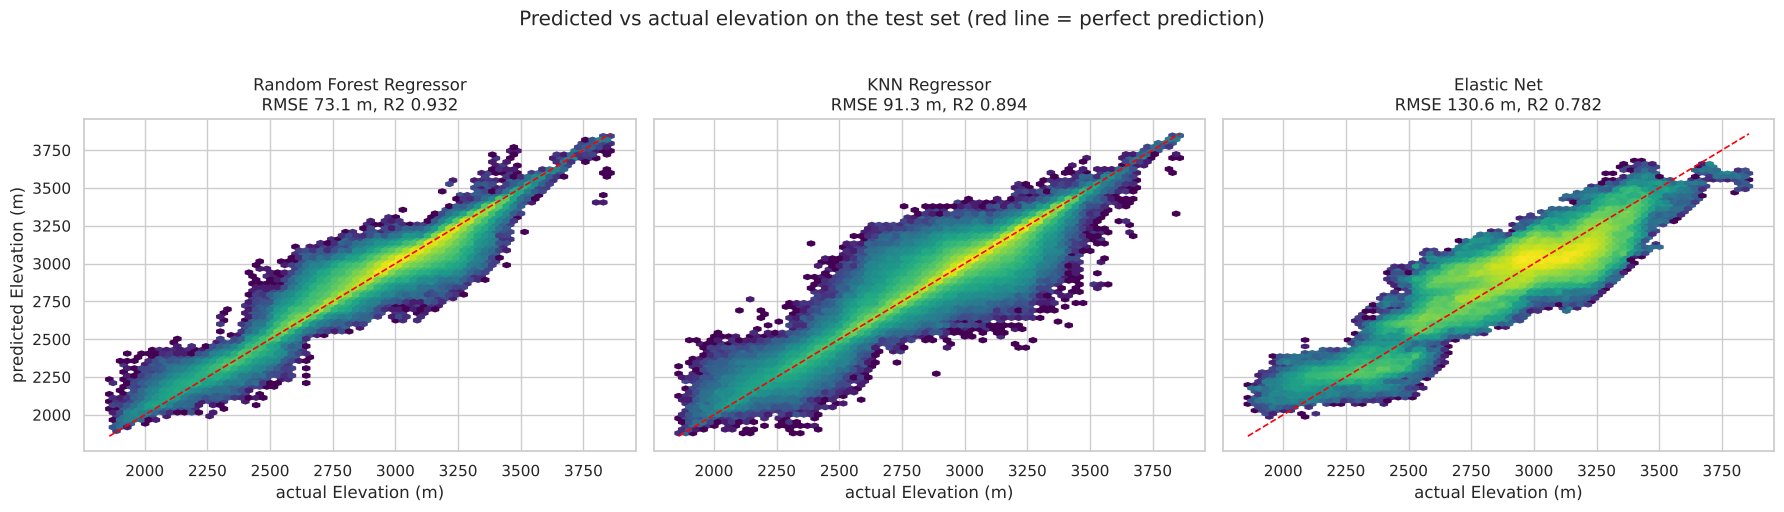

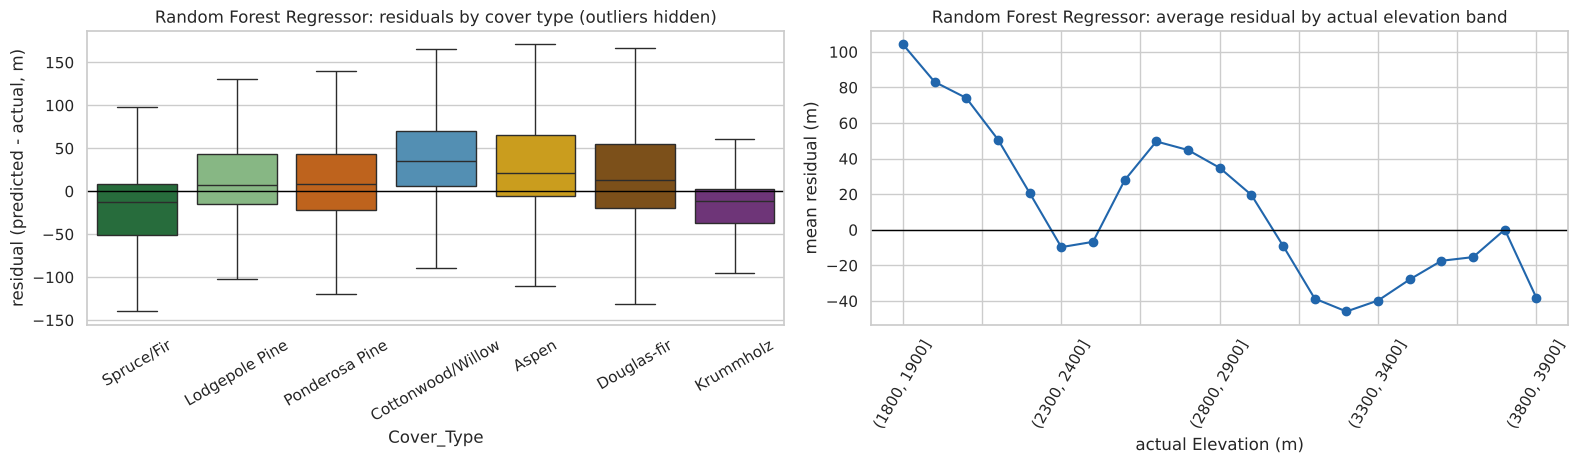

In [ ]:
best_reg = test_reg['RMSE (m)'].idxmin()
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
lims = (y_test_r.min(), y_test_r.max())
for ax, name in zip(axes, reg_names):
    ax.hexbin(y_test_r, test_pred[name], gridsize=70, cmap='viridis', mincnt=1, bins='log')
    ax.plot(lims, lims, color='red', linewidth=1.2, linestyle='--')
    ax.set_title(f'{name}\nRMSE {test_reg.loc[name, "RMSE (m)"]:.1f} m, R2 {test_reg.loc[name, "R2"]:.3f}')
    ax.set_xlabel('actual Elevation (m)')
axes[0].set_ylabel('predicted Elevation (m)')
plt.suptitle('Predicted vs actual elevation on the test set (red line = perfect prediction)', y=1.02)
plt.tight_layout()
plt.show()

resid = pd.DataFrame({'residual (predicted - actual, m)': test_pred[best_reg] - y_test_r.values,
                      'Cover_Type': y_test_c.map(cover_type_names).values,
                      'actual Elevation (m)': y_test_r.values})
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
order = [cover_type_names[k] for k in cover_type_names]
sns.boxplot(data=resid, x='Cover_Type', y='residual (predicted - actual, m)', order=order, ax=axes[0],
            palette=[cover_type_colors[k] for k in cover_type_names], showfliers=False)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title(f'{best_reg}: residuals by cover type (outliers hidden)')
axes[0].tick_params(axis='x', rotation=30)
bins = pd.cut(resid['actual Elevation (m)'], bins=np.arange(1800, 4000, 100))
resid.groupby(bins, observed=True)['residual (predicted - actual, m)'].mean().plot(ax=axes[1], marker='o', color='#2166ac')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title(f'{best_reg}: average residual by actual elevation band')
axes[1].set_ylabel('mean residual (m)')
axes[1].tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

The hexbin plots show the difference between the models at a glance. The random forest's predictions hug the red line across the whole range. KNN is similar but with a wider cloud. The elastic net's cloud is much wider and visibly flattened. It overpredicts the lowest cells and underpredicts the highest ones, and it forms stepped clusters because a big part of its prediction comes from which soil type a cell has. That flattening is what a straight line fit looks like when the real relationship is curved.

The residual plots for the random forest show where even the best model struggles:

- **By cover type**, Cottonwood/Willow and Aspen cells tend to be predicted too high (median errors around +35 m and +20 m), while Spruce/Fir and Krummholz are predicted slightly too low. The model doesn't know the cover type, so it can't tell that a riparian cottonwood stand sits lower than the terrain around it suggests.
- **By elevation band**, the lowest cells (1,800 to 2,100 m) are overpredicted by 75 to 105 m on average, and the cells around 3,200 to 3,400 m are underpredicted by about 40 m. This is regression toward the middle. A forest averages its training cells, and at the extremes most of the nearby training cells are less extreme.

For the data quality use case this matters. A single cutoff like "flag anything more than 200 m off" would flag too many correct low elevation cells. A better rule would compare each residual to the typical residual for its own elevation band.

<a id="sec-3-5-advantages-of-each-model-and-are-the-differences-significant"></a>
### 3.5 Advantages of each model, and are the differences significant?

**Which test?** Our 10 fold scores are paired, because every model was scored on the exact same folds. A plain paired t-test on them is the common choice, but it's wrong here. The training sets of different folds overlap by about 89%, so the ten scores are not independent, and the plain test underestimates the variance and finds "significant" differences far too often (Dietterich, 1998). We use the **corrected resampled t-test** of Nadeau and Bengio (2003), which inflates the variance term to account for that overlap. It gives a t statistic with 9 degrees of freedom and a 95% confidence interval for the difference in mean score.

We compare every pair of models, which is 10 tests for the classifiers and 3 for the regressors. With that many tests, some will look significant by chance, so we adjust the p values with the Holm (1979) method and call a difference significant only when the adjusted p value is below 0.05.

As a second, independent check for the classifiers, we run **McNemar's test** (McNemar, 1947) on the held out test set. It looks only at the rows where exactly one of the two models is right and asks whether those disagreements are lopsided. With over half a million test rows it has a lot of power, so it will flag even small differences, and we read it alongside the size of the difference.

In [ ]:
# Corrected resampled t-test, Nadeau and Bengio (2003). The (n_test / n_train) term corrects
# the variance for the overlap between training sets across folds.
def corrected_resampled_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    se = np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    t = d.mean() / se
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    half = stats.t.ppf(0.975, df=k - 1) * se
    return d.mean(), d.mean() - half, d.mean() + half, t, p

# Holm (1979) step down adjustment for multiple comparisons
def holm(pvals):
    p = np.asarray(pvals)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj

n_te = N_DEV / CV_FOLDS
n_tr = N_DEV - n_te

def pairwise_table(scores, names, higher_is_better=True):
    rows = []
    for a, b in itertools.combinations(names, 2):
        diff, lo, hi, t, p = corrected_resampled_ttest(scores[a], scores[b], n_tr, n_te)
        rows.append({'model A': a, 'model B': b, 'mean diff (A - B)': diff,
                     '95% CI low': lo, '95% CI high': hi, 't': t, 'p': p})
    out = pd.DataFrame(rows)
    out['p (Holm)'] = holm(out['p'])
    out['significant at 95%'] = np.where(out['p (Holm)'] < 0.05, 'yes', 'no')
    better = (out['mean diff (A - B)'] > 0) == higher_is_better
    out['better model'] = np.where(out['significant at 95%'] == 'yes',
                                   np.where(better, out['model A'], out['model B']), 'no clear winner')
    return out

ttest_clf = pairwise_table({n: cv_clf[n]['test_f1_macro'] for n in clf_names}, clf_names)
ttest_reg = pairwise_table({n: -cv_reg[n]['test_neg_root_mean_squared_error'] for n in reg_names},
                           reg_names, higher_is_better=False)
print('Classification, macro F1 over 10 folds:')
display(ttest_clf.round(4))
print('Regression, RMSE (m) over 10 folds:')
display(ttest_reg.round(3))

Classification, macro F1 over 10 folds:


,model A,model B,mean diff (A - B),95% CI low,95% CI high,t,p,p (Holm),significant at 95%,better model
0,Decision Tree,Random Forest,-0.0815,-0.0960,-0.0671,-12.7566,0.0000,0.0000,yes,Random Forest
1,Decision Tree,Weighted Random Forest,-0.0642,-0.0752,-0.0532,-13.2144,0.0000,0.0000,yes,Weighted Random Forest
2,Decision Tree,KNN,-0.0073,-0.0262,0.0115,-0.8797,0.4019,0.7065,no,no clear winner
3,Decision Tree,Gradient Boosting,-0.0881,-0.0998,-0.0764,-16.9919,0.0000,0.0000,yes,Gradient Boosting
4,Decision Tree,Extra Trees,-0.1063,-0.1168,-0.0957,-22.7825,0.0000,0.0000,yes,Extra Trees
5,Decision Tree,LightGBM,-0.0940,-0.1056,-0.0825,-18.4123,0.0000,0.0000,yes,LightGBM
6,Random Forest,Weighted Random Forest,0.0173,0.0032,0.0315,2.7671,0.0219,0.1093,no,no clear winner
7,Random Forest,KNN,0.0742,0.0485,0.0999,6.5204,0.0001,0.0010,yes,Random Forest
8,Random Forest,Gradient Boosting,-0.0066,-0.0217,0.0086,-0.9831,0.3513,0.7065,no,no clear winner
9,Random Forest,Extra Trees,-0.0248,-0.0369,-0.0127,-4.6366,0.0012,0.0098,yes,Extra Trees


Regression, RMSE (m) over 10 folds:


,model A,model B,mean diff (A - B),95% CI low,95% CI high,t,p,p (Holm),significant at 95%,better model
0,Random Forest Regressor,KNN Regressor,-18.404,-19.692,-17.116,-32.324,0.0,0.0,yes,Random Forest Regressor
1,Random Forest Regressor,Elastic Net,-56.348,-57.849,-54.846,-84.891,0.0,0.0,yes,Random Forest Regressor
2,KNN Regressor,Elastic Net,-37.943,-39.768,-36.119,-47.049,0.0,0.0,yes,KNN Regressor


In [ ]:
# McNemar's test with continuity correction (McNemar, 1947; Dietterich, 1998)
def mcnemar(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    only_a, only_b = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
    chi2 = (abs(only_a - only_b) - 1) ** 2 / (only_a + only_b)
    return only_a, only_b, chi2, stats.chi2.sf(chi2, df=1)

y_arr = y_test_c.to_numpy()
rows = []
for a, b in itertools.combinations(clf_names, 2):
    only_a, only_b, chi2, p = mcnemar(y_arr, test_pred[a], test_pred[b])
    rows.append({'model A': a, 'model B': b, 'rows only A right': only_a, 'rows only B right': only_b,
                 'chi2': chi2, 'p': p})
mcn = pd.DataFrame(rows)
mcn['p (Holm)'] = holm(mcn['p'])
mcn['significant at 95%'] = np.where(mcn['p (Holm)'] < 0.05, 'yes', 'no')
mcn.round(4)

,model A,model B,rows only A right,rows only B right,chi2,p,p (Holm),significant at 95%
0,Decision Tree,Random Forest,21699,55633,14889.6768,0.0,0.0,yes
1,Decision Tree,Weighted Random Forest,37098,54943,3459.4185,0.0,0.0,yes
2,Decision Tree,KNN,46349,56130,933.3463,0.0,0.0,yes
3,Decision Tree,Gradient Boosting,27193,57076,10596.2326,0.0,0.0,yes
4,Decision Tree,Extra Trees,18724,60174,21775.1984,0.0,0.0,yes
5,Decision Tree,LightGBM,21672,58722,17073.7667,0.0,0.0,yes
6,Random Forest,Weighted Random Forest,29517,13428,6026.8656,0.0,0.0,yes
7,Random Forest,KNN,44399,20246,9023.4218,0.0,0.0,yes
8,Random Forest,Gradient Boosting,18669,14618,492.7599,0.0,0.0,yes
9,Random Forest,Extra Trees,8962,16478,2219.9381,0.0,0.0,yes


**What the corrected t-tests say (macro F1, 10 folds).** The models fall into clear tiers.

With seven classifiers there are 21 pairs, and the Holm correction accounts for all of them.

- **Extra trees is significantly better than the random forest**, by 0.025 in macro F1 (95% CI 0.013 to 0.037, Holm p = 0.010), and better than the weighted random forest, KNN and the decision tree.
- **Its lead over gradient boosting and LightGBM is not significant after the correction.** It's ahead of gradient boosting by 0.018 (CI 0.005 to 0.031) and of LightGBM by 0.012 (CI 0.003 to 0.022). Both intervals exclude zero on their own, but with 21 comparisons the Holm adjusted p values are 0.076 and 0.109. So on the cross validation evidence alone, extra trees, LightGBM, gradient boosting and the plain random forest form a top group, with extra trees at the front.
- Inside that group the other differences are small and not significant. Gradient boosting and LightGBM are 0.006 apart, and the random forest is within 0.013 of both.
- The weighted random forest sits a step lower. Gradient boosting, LightGBM and extra trees all beat it, and it ties with the plain random forest (Holm p = 0.109).
- All the ensembles beat the decision tree and KNN by 0.06 to 0.11, and all of those differences are significant.
- **Bottom tier: the decision tree and KNN are tied** (p = 0.71).

**For regression every difference is significant.** The random forest beats KNN by 18.4 m of RMSE (CI 17.1 to 19.7 m) and beats the elastic net by 56.3 m (CI 54.8 to 57.8 m). KNN beats the elastic net by 37.9 m.

**What McNemar adds.** On the test set, every pair is significantly different. That's partly the sheer size of the test set, since with half a million rows even tiny differences become detectable. It also measures something different: McNemar only counts right versus wrong, which is accuracy, not macro F1.

The test set backs up extra trees clearly. Against gradient boosting, extra trees is right on 24,708 rows where boosting is wrong, and boosting is right on only 13,141 rows where extra trees is wrong. Against LightGBM the split is 18,175 to 13,775 in favor of extra trees. So the gaps that fell just short after the Holm correction in cross validation do hold up on half a million unseen rows.

Among the original five, the random forest and gradient boosting show why both tests are needed. The forest is right on 18,669 rows where boosting is wrong, and boosting is right on only 14,618 rows where the forest is wrong. So the forest is more accurate overall, while boosting does better on the small classes that macro F1 rewards.

**Advantages of each model, by task.**

*Classification:*
- **Decision tree.** Trains in under a second and can be printed as a set of rules. It's the weakest model here, though, because one deep tree memorizes noise.
- **Random forest.** Strong on the two big classes and easy to tune. It takes about twice as long to train as the weighted forest with our settings, but prediction is fast. Extra trees now beats it on every overall metric.
- **Weighted random forest.** Best at finding the rare cover types, especially Aspen, Ponderosa Pine and Krummholz, and fastest of the ensembles to train. It gives up some accuracy on Lodgepole Pine in return.
- **Gradient boosting.** The best of the original five on macro F1, with quick training and prediction. It has the most hyperparameters, and Section 5.1 shows the learning rate needs care.
- **Extra trees.** The best classifier overall on macro F1, accuracy and balanced accuracy, and it trains faster than the random forest. The random split points make each tree weaker but the trees more different from each other, which helps on data like this, where cover types change in small patches.
- **LightGBM.** Second on macro F1 and a close match for gradient boosting, built on the same idea. It's fast to train, and its trees grow leaf by leaf, which suits detailed class boundaries like these. In our setup it predicts slowly, because we keep it to one thread so the results repeat exactly.
- **KNN.** No training at all and good at local patterns, but it ties with the single decision tree and is one of the slowest to predict. Of our seven, it's the hardest to justify for this data.

*Regression:*
- **Random forest regressor.** Most accurate by a wide, significant margin. It handles the curved, banded relationship between soil, location and elevation that the linear model can't capture.
- **KNN regressor.** Second best and trivial to train. Slow to predict, like the classifier.
- **Elastic net.** By far the least accurate, but it's the only one of the three whose predictions can be explained with a coefficient table, it predicts the whole test set in a fraction of a second, and it gives a clean benchmark. The 56 m gap to the forest shows how much of elevation is nonlinear.

<a id="sec-do-the-forests-need-more-training-data"></a>
#### Do the forests need more training data?

Moinak's notebook (Ghosh, 2026) trained the same two forests on a 60% / 20% / 20% train, validation and test split of the full data, so about 349,000 training rows instead of our 50,000. He used fixed settings (150 trees, `max_depth=24`, `min_samples_leaf=2`, `max_features='sqrt'`) with no tuning step, and his scores were well above ours. Our models differ from his in two ways, the amount of training data and the tuning, so we test both here. We recreate his split with our seed and fit four forests on the 60% training part: his settings and our tuned settings, each with and without class weights. All four use our prepared features.

One caveat. Our hyperparameters were picked on 15,000 rows that can also fall inside this new test split. That's a small amount of reuse for a handful of discrete settings, and it doesn't affect the comparison between data sizes.

In [ ]:
# Training size check, recreating the 60/20/20 split from Moinak Ghosh's notebook (Group 3)
# with his fixed forest settings next to our tuned ones.
idx_tr60, idx_rest = train_test_split(df.index, test_size=0.40, stratify=df['Cover_Type'],
                                      random_state=RANDOM_STATE)
idx_val20, idx_te20 = train_test_split(idx_rest, test_size=0.50, stratify=df.loc[idx_rest, 'Cover_Type'],
                                       random_state=RANDOM_STATE)
print(f'train {len(idx_tr60):,} | validation {len(idx_val20):,} | test {len(idx_te20):,}')

moinak_settings = dict(n_estimators=150, max_depth=24, min_samples_leaf=2, max_features='sqrt',
                       n_jobs=N_JOBS, random_state=RANDOM_STATE)
candidates = {
    'Random Forest, Moinak settings': lambda: RandomForestClassifier(**moinak_settings),
    'Weighted Random Forest, Moinak settings': lambda: RandomForestClassifier(**moinak_settings, class_weight='balanced'),
    'Random Forest, our tuned settings': lambda: build_model('Random Forest'),
    'Weighted Random Forest, our tuned settings': lambda: build_model('Weighted Random Forest'),
}
X_tr60, y_tr60 = df.loc[idx_tr60, clf_features], df.loc[idx_tr60, 'Cover_Type']
y_val20, y_te20 = df.loc[idx_val20, 'Cover_Type'], df.loc[idx_te20, 'Cover_Type']

big_rows, big_pred = [], {}
for name, make in candidates.items():
    model = make()
    t0 = time.time(); model.fit(X_tr60, y_tr60); fit_s = time.time() - t0
    val_pred = model.predict(df.loc[idx_val20, clf_features])
    big_pred[name] = model.predict(df.loc[idx_te20, clf_features])
    val_m, test_m = clf_metrics(y_val20, val_pred), clf_metrics(y_te20, big_pred[name])
    big_rows.append({'model': name, 'validation macro F1': val_m['macro F1'], 'test macro F1': test_m['macro F1'],
                     'test accuracy': test_m['accuracy'], 'test balanced accuracy': test_m['balanced accuracy'],
                     'fit (s)': round(fit_s)})
    del model
    print(f'{name:<44} test macro F1 {test_m["macro F1"]:.4f}   ({fit_s:.0f}s)')

big_tbl = pd.DataFrame(big_rows).set_index('model')
big_tbl.loc['(for reference) Weighted Random Forest, tuned, 50k training rows'] = [
    np.nan, test_clf.loc['Weighted Random Forest', 'macro F1'], test_clf.loc['Weighted Random Forest', 'accuracy'],
    test_clf.loc['Weighted Random Forest', 'balanced accuracy'], np.nan]
display(big_tbl.round(4))

train 348,607 | validation 116,202 | test 116,203


Random Forest, Moinak settings               test macro F1 0.8690   (45s)


Weighted Random Forest, Moinak settings      test macro F1 0.8683   (33s)


Random Forest, our tuned settings            test macro F1 0.9282   (271s)


Weighted Random Forest, our tuned settings   test macro F1 0.9127   (66s)


,validation macro F1,test macro F1,test accuracy,test balanced accuracy,fit (s)
model,,,,,
"Random Forest, Moinak settings",0.8722,0.8690,0.9128,0.8322,45.0
"Weighted Random Forest, Moinak settings",0.8682,0.8683,0.9048,0.9260,33.0
"Random Forest, our tuned settings",0.9262,0.9282,0.9564,0.9090,271.0
"Weighted Random Forest, our tuned settings",0.9106,0.9127,0.9364,0.9260,66.0
"(for reference) Weighted Random Forest, tuned, 50k training rows",NaN,0.8171,0.8636,0.8304,NaN


In [ ]:
# Paired comparisons on the 20% test split: bootstrap 95% CI for the macro F1 difference, plus McNemar
def macro_f1_fast(t, p, k=7):
    # Macro F1 from confusion counts, fast enough for 1,000 bootstrap resamples
    cm = np.bincount(t * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    return np.mean(np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0))

y_te20_idx = y_te20.to_numpy().astype(int) - 1
def compare_big(a, b, n_boot=1000):
    pa, pb = big_pred[a].astype(int) - 1, big_pred[b].astype(int) - 1
    rng = np.random.default_rng(RANDOM_STATE)
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_te20_idx), len(y_te20_idx))
        boot.append(macro_f1_fast(y_te20_idx[i], pa[i]) - macro_f1_fast(y_te20_idx[i], pb[i]))
    only_a, only_b, chi2, p = mcnemar(y_te20.to_numpy(), big_pred[a], big_pred[b])
    return {'model A': a, 'model B': b,
            'macro F1 diff (A - B)': macro_f1_fast(y_te20_idx, pa) - macro_f1_fast(y_te20_idx, pb),
            '95% CI low': np.percentile(boot, 2.5), '95% CI high': np.percentile(boot, 97.5),
            'rows only A right': only_a, 'rows only B right': only_b, 'McNemar p': p}

pairs = [('Weighted Random Forest, our tuned settings', 'Random Forest, our tuned settings'),
         ('Weighted Random Forest, our tuned settings', 'Weighted Random Forest, Moinak settings'),
         ('Random Forest, our tuned settings', 'Random Forest, Moinak settings')]
display(pd.DataFrame([compare_big(a, b) for a, b in pairs]).round(4))

,model A,model B,macro F1 diff (A - B),95% CI low,95% CI high,rows only A right,rows only B right,McNemar p
0,"Weighted Random Forest, our tuned settings","Random Forest, our tuned settings",-0.0154,-0.0185,-0.0123,1274,3604,0.0
1,"Weighted Random Forest, our tuned settings","Weighted Random Forest, Moinak settings",0.0445,0.0412,0.0474,4231,563,0.0
2,"Random Forest, our tuned settings","Random Forest, Moinak settings",0.0592,0.0557,0.0627,5597,529,0.0


**More training data helps a lot.** Our tuned weighted forest goes from a test macro F1 of 0.817 with 50,000 training rows to 0.913 with about 349,000. The tuned plain forest reaches 0.928, with 95.6% accuracy. That jump is about as large as the gap between our best and worst classifiers, so the forests are clearly limited by data at the 50,000 row size we used for the main comparison. This doesn't change our choice of a small training set for the main analysis, since we wanted a realistic survey budget and room for 10 fold cross validation of every model. It does tell a land manager something useful. Every extra labeled cell keeps paying off well past 50,000.

**Tuning matters too.** On the same 349,000 training rows, our tuned settings beat Moinak's fixed settings by 0.059 in macro F1 for the plain forest (95% CI 0.056 to 0.063) and by 0.045 for the weighted forest (95% CI 0.041 to 0.047). McNemar's test agrees for both, by a wide margin. This matches the grid search analysis in Section 5.1. Leaf size was the most important random forest hyperparameter, and Moinak's settings use a minimum leaf size of 2 with a depth cap of 24. Ours use a leaf size of 1, and for the plain forest half the features at each split. His settings were a reasonable starting point, but the grid search improved on that.

**The ranking of the two forests holds at both sizes.** With 349,000 training rows the plain forest still has the higher macro F1, ahead by 0.015 (95% CI 0.012 to 0.019), and the weighted forest still has the higher balanced accuracy (0.926 vs 0.909). So the trade we saw at 50,000 rows isn't a small sample effect. Class weighting buys recall on the rare classes and pays for it in precision.

Validation and test scores agree within 0.003 for all four models, so these results are stable.

<a id="sec-3-6-which-attributes-matter-most"></a>
### 3.6 Which attributes matter most?

**Method.** Our main tool is **permutation importance** (Breiman, 2001). Take a fitted model and a set of test rows, shuffle one feature's column so it no longer lines up with the target, and measure how much the score drops. A big drop means the model relied on that feature. It works the same way for every model, including KNN, which has no built in importance, so it's the fair way to compare across our ten models. We compute it on 5,000 held out test rows, with three shuffles per feature.

We shuffle some columns **as groups**. The four `Wilderness_Area` flags are shuffled together as one block, and so are the `Soil_Type` flags. Shuffling one soil flag alone would create impossible rows with two soil types or none, and each single flag would look unimportant even if soil type as a whole matters a lot. For the same reason `aspect_sin` and `aspect_cos` form one "Aspect" group, and the three water distance columns form one "Hydrology" group.

For comparison, we also show the random forest's built in impurity importance. It's known to favor continuous features with many possible split points over binary flags (Strobl et al., 2007), so we treat it as a second opinion. For elastic net we also look at the coefficients directly.

permutation importance done in 186s


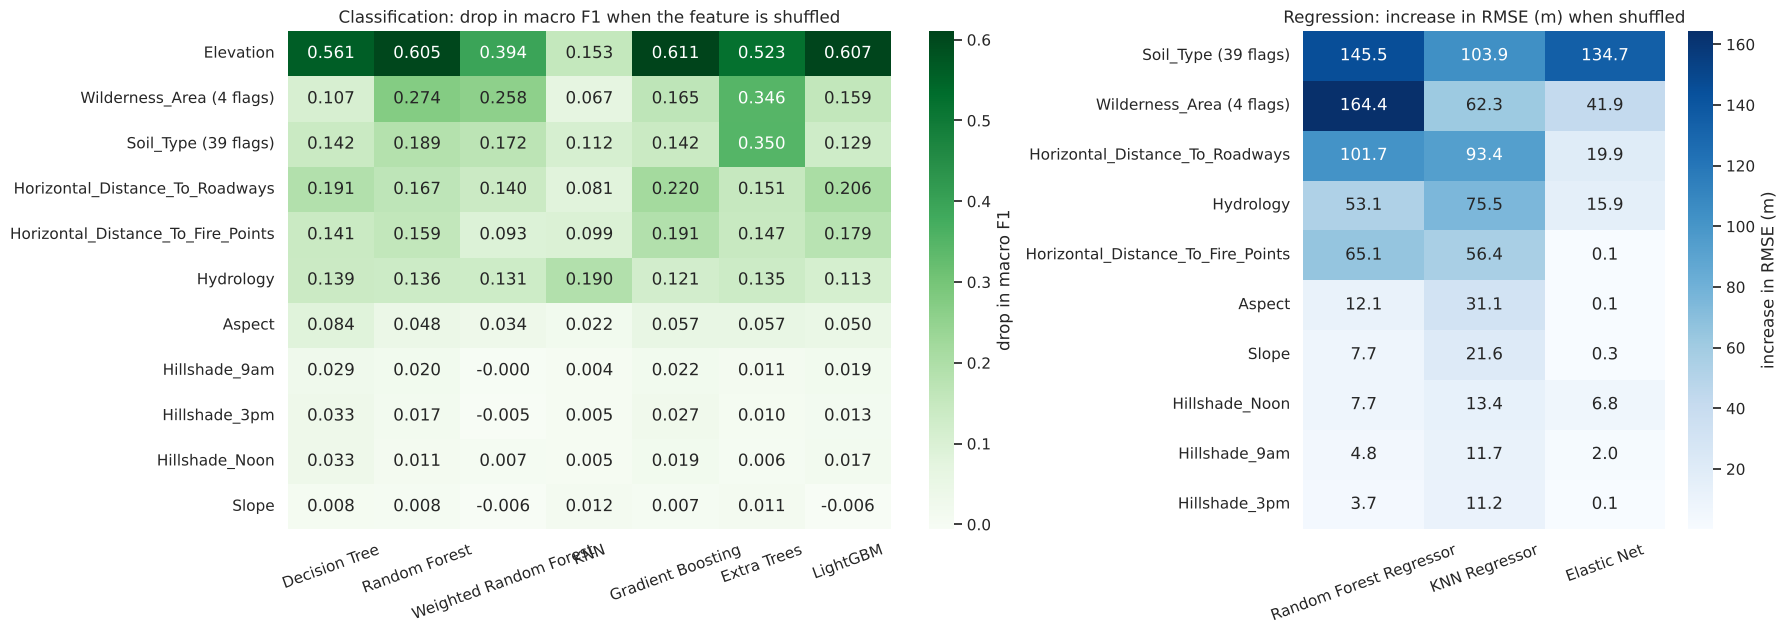

In [ ]:
perm_idx, _ = train_test_split(idx_test, train_size=N_PERM, stratify=df.loc[idx_test, 'Cover_Type'],
                               random_state=RANDOM_STATE)

feature_groups = {'Elevation': ['Elevation'], 'Slope': ['Slope'], 'Aspect': ['aspect_sin', 'aspect_cos'],
                  'Hydrology': ['Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'hydro_distance'],
                  'Horizontal_Distance_To_Roadways': ['Horizontal_Distance_To_Roadways'],
                  'Horizontal_Distance_To_Fire_Points': ['Horizontal_Distance_To_Fire_Points'],
                  'Hillshade_9am': ['Hillshade_9am'], 'Hillshade_Noon': ['Hillshade_Noon'],
                  'Hillshade_3pm': ['Hillshade_3pm'], 'Wilderness_Area (4 flags)': wild_cols,
                  f'Soil_Type ({len(soil_keep)} flags)': soil_keep}

# Permutation importance (Breiman, 2001), adapted so that a group of columns is shuffled together
def grouped_permutation_importance(model, X, y, groups, score_fn, n_repeats=3, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = score_fn(y, model.predict(X))
    result = {}
    for gname, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            drops.append(base - score_fn(y, model.predict(Xp)))
        result[gname] = np.mean(drops)
    return pd.Series(result)

macro_f1 = lambda y, p: f1_score(y, p, average='macro', zero_division=0)
neg_rmse = lambda y, p: -np.sqrt(mean_squared_error(y, p))

reg_groups = {k: v for k, v in feature_groups.items() if k != 'Elevation'}
X_perm_c, y_perm_c = df.loc[perm_idx, clf_features], df.loc[perm_idx, 'Cover_Type']
X_perm_r, y_perm_r = df.loc[perm_idx, reg_features], df.loc[perm_idx, 'Elevation']

start = time.time()
imp_clf = pd.DataFrame({n: grouped_permutation_importance(fitted[n], X_perm_c, y_perm_c, feature_groups, macro_f1)
                        for n in clf_names})
imp_reg = pd.DataFrame({n: grouped_permutation_importance(fitted[n], X_perm_r, y_perm_r, reg_groups, neg_rmse)
                        for n in reg_names})
print(f'permutation importance done in {time.time() - start:.0f}s')

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={'width_ratios': [5, 3]})
imp_c = imp_clf.loc[imp_clf.mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(imp_c, annot=True, fmt='.3f', cmap='Greens', ax=axes[0], cbar_kws={'label': 'drop in macro F1'})
axes[0].set_title('Classification: drop in macro F1 when the feature is shuffled')
axes[0].tick_params(axis='x', rotation=20)
imp_r = imp_reg.loc[imp_reg.mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(imp_r, annot=True, fmt='.1f', cmap='Blues', ax=axes[1], cbar_kws={'label': 'increase in RMSE (m)'})
axes[1].set_title('Regression: increase in RMSE (m) when shuffled')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

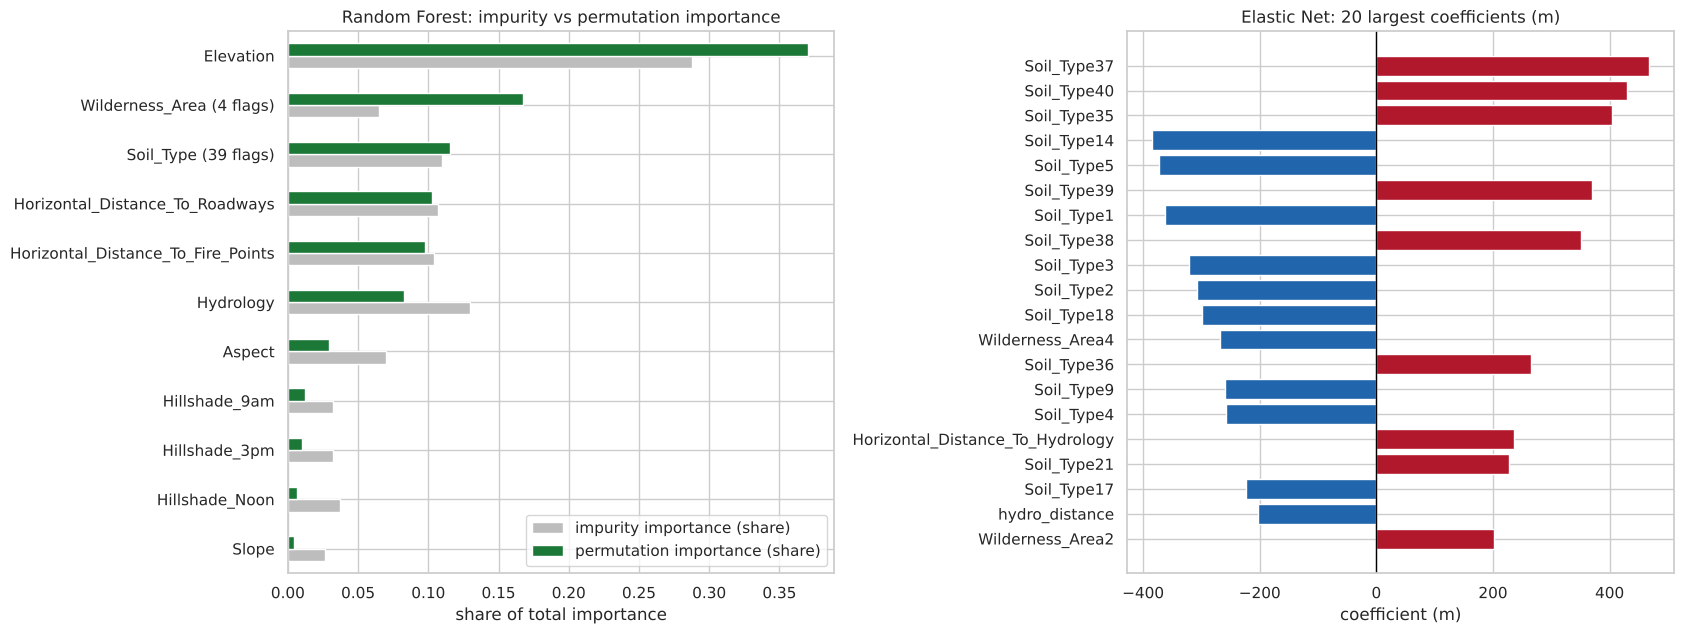

Elastic net kept 54 of 54 coefficients nonzero (alpha = 0.0001, l1_ratio = 0.9)


In [ ]:
# Built in impurity importance for the random forest, summed into the same groups
rf_mdi = pd.Series(fitted['Random Forest'].feature_importances_, index=clf_features)
mdi_grouped = pd.Series({g: rf_mdi[cols].sum() for g, cols in feature_groups.items()})
compare = pd.DataFrame({'impurity importance (share)': mdi_grouped / mdi_grouped.sum(),
                        'permutation importance (share)': imp_clf['Random Forest'].clip(lower=0) / imp_clf['Random Forest'].clip(lower=0).sum()})
compare = compare.sort_values('permutation importance (share)')

# Elastic net coefficients: continuous inputs are standardized, so their coefficient is meters per
# one standard deviation. Flag coefficients are meters for being in that area or soil type.
enet_pipe = fitted['Elastic Net']
coef = pd.Series(enet_pipe.named_steps['enet'].coef_,
                 index=[n.split('__', 1)[1] for n in enet_pipe.named_steps['scale'].get_feature_names_out()])
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(20)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
compare.plot.barh(ax=axes[0], color=['#bdbdbd', '#1b7837'])
axes[0].set_title('Random Forest: impurity vs permutation importance')
axes[0].set_xlabel('share of total importance')
axes[1].barh(top_coef.index, top_coef.values, color=np.where(top_coef.values > 0, '#b2182b', '#2166ac'))
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Elastic Net: 20 largest coefficients (m)')
axes[1].set_xlabel('coefficient (m)')
plt.tight_layout()
plt.show()
print(f'Elastic net kept {int((coef != 0).sum())} of {len(coef)} coefficients nonzero '
      f'(alpha = {best_params["Elastic Net"]["enet__alpha"]:.4g}, l1_ratio = {best_params["Elastic Net"]["enet__l1_ratio"]})')

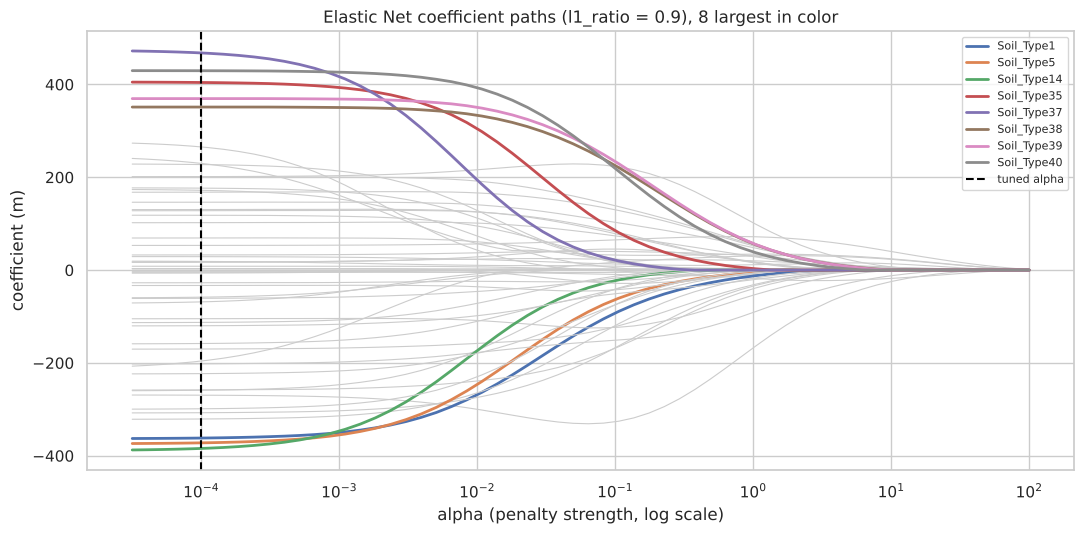

In [ ]:
# Coefficient path: how each elastic net coefficient shrinks as the penalty grows.
# Inputs and target are centered first because enet_path fits without an intercept.
Xs = enet_pipe.named_steps['scale'].transform(X_dev_r)
Xs = Xs - Xs.mean(axis=0)
l1 = best_params['Elastic Net']['enet__l1_ratio']
alphas, paths, _ = enet_path(Xs, (y_dev_r - y_dev_r.mean()).to_numpy(), l1_ratio=l1,
                             alphas=np.logspace(2, -4.5, 60))

show = coef.abs().sort_values(ascending=False).head(8).index
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, name in enumerate(coef.index):
    if name in show:
        ax.plot(alphas, paths[i], linewidth=2, label=name)
    else:
        ax.plot(alphas, paths[i], color='#cccccc', linewidth=0.8)
ax.axvline(best_params['Elastic Net']['enet__alpha'], color='black', linestyle='--', label='tuned alpha')
ax.set_xscale('log')
ax.set_xlabel('alpha (penalty strength, log scale)'); ax.set_ylabel('coefficient (m)')
ax.set_title(f'Elastic Net coefficient paths (l1_ratio = {l1}), 8 largest in color')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

**Classification.** Elevation is the most important feature for every tree based model by a wide margin. Shuffling it drops macro F1 by 0.56 to 0.61 for the decision tree, random forest, gradient boosting and LightGBM. That makes sense biologically. Elevation controls temperature, snow cover and the length of the growing season, and each species has its own band, from Ponderosa Pine and Cottonwood/Willow at the bottom to Krummholz at the treeline.

The next group is location and soil: the wilderness area, the distance to roads, the soil type, the distance to fire points and the distance to water. Wilderness area matters because the four areas are very different places. Wilderness_Area4 (average elevation 2,294 m) holds every Cottonwood/Willow cell in the data and most of the Ponderosa Pine and Douglas-fir, while Wilderness_Area2 sits highest at an average of 3,246 m. Road and fire point distances probably work as stand ins for location inside the forest and for human access and burn history. Lodgepole Pine in particular regrows after fire. Water distance separates streamside cells, where cottonwood and willow grow, from dry slopes.

Slope and the three hillshade columns barely matter for any model, and a few of their scores are slightly below zero, which is just noise. Hillshade is calculated from slope and aspect, so it repeats information the models already have. That makes them candidates to drop from a simpler classifier, although we didn't test it, and permutation importance understates features that share information with others.

Extra trees spreads its reliance more evenly. Elevation is still its top feature (0.52), but soil type (0.35) matters about twice as much to it as to the other ensembles, and wilderness area (0.35) matters more to it than to any other model. There's a simple reason. Extra trees picks each split point at random between a feature's smallest and largest value. For a 0/1 flag any point between 0 and 1 gives the same perfect split, so the randomness costs nothing there. For a continuous feature like Elevation, a random cut point is usually worse than the best one. So extra trees gets more out of the soil and wilderness flags than the other models do, and that's likely part of why it comes out on top.

KNN is the other exception. No single feature dominates it, and water distance is its top group. KNN measures distance across all standardized features at once, so it can't focus on Elevation the way a tree can by splitting on it first. That's probably a big part of why KNN trails the tree models.

The random forest comparison shows the bias we expected. Impurity importance gives more credit to the continuous columns with many split points (water distance, Aspect, the hillshades and Slope) and less to the binary wilderness flags, compared to permutation importance (Strobl et al., 2007). If we had used the built in importances alone, we would have understated how much wilderness area matters.

**Regression.** Without Elevation as an input, soil type becomes the most important group for all three models. Shuffling it adds 104 to 146 m of RMSE. Wilderness area is also huge for the random forest (164 m). The reason is in the soil codes. Each soil type in the dataset documentation has an ELU code whose first digit is a climatic zone, from lower montane to subalpine and alpine, and those zones are defined largely by altitude. So the soil flags quietly carry a coarse elevation map. The elastic net coefficients show this directly. Its largest positive coefficients are Soil_Type35, 37, 38, 39 and 40, which are all subalpine soils (ELU codes starting with 8). Its largest negative ones are Soil_Type1 to 5, which are lower montane soils (codes starting with 2). Road distance and water distance come next.

One warning about reading the elastic net coefficients one at a time. `Horizontal_Distance_To_Hydrology` has a large positive coefficient and `hydro_distance` a large negative one. The two are highly correlated, so the model is mostly using their difference, and neither coefficient means much alone. The path plot shows how the coefficients shrink as the penalty grows. The subalpine soils `Soil_Type38`, `Soil_Type39` and `Soil_Type40` hold their large coefficients the longest, which confirms they carry the strongest signal. The lower montane soils shrink a bit sooner, and `Soil_Type37` drops off early, likely because it shares its information with the other subalpine soils. At our tuned alpha the penalty is so small that all 54 coefficients stay nonzero.

<a id="sec-sensitivity-check-the-elevation-model-without-soil-type"></a>
#### Sensitivity check: the elevation model without soil type

Soil type turned out to be the strongest input for predicting elevation, and the reason is that its ELU codes carry climatic zones that are partly defined by altitude. We kept it because soil maps are real map data that a user would have. But we want to know how much of the regression result depends on it. So we rerun the 10 fold cross validation of the tuned random forest regressor with all 39 `Soil_Type` flags removed, on exactly the same folds, and compare with the corrected resampled t-test from Section 3.5.

In [ ]:
no_soil = [c for c in reg_features if c not in soil_keep]
start = time.time()
rf_no_soil = cross_validate(build_model('Random Forest Regressor'), X_dev_r[no_soil], y_dev_r, cv=kf,
                            n_jobs=1, scoring=reg_scoring)
with_soil = cv_reg['Random Forest Regressor']
rows = {}
for label, res, n_in in [('with Soil_Type flags', with_soil, len(reg_features)),
                         ('without Soil_Type flags', rf_no_soil, len(no_soil))]:
    rows[label] = {'inputs': n_in,
                   'RMSE (m)': -res['test_neg_root_mean_squared_error'].mean(),
                   'MAE (m)': -res['test_neg_mean_absolute_error'].mean(),
                   'R2': res['test_r2'].mean()}
display(pd.DataFrame(rows).T.round(3))

diff, lo, hi, t, p = corrected_resampled_ttest(-rf_no_soil['test_neg_root_mean_squared_error'],
                                               -with_soil['test_neg_root_mean_squared_error'], n_tr, n_te)
print(f'Removing the soil flags adds {diff:.1f} m of RMSE '
      f'(95% CI {lo:.1f} to {hi:.1f} m, corrected t-test p = {p:.2g})   ({time.time() - start:.0f}s)')

,inputs,RMSE (m),MAE (m),R2
with Soil_Type flags,54.0,74.023,49.324,0.930
without Soil_Type flags,15.0,122.559,86.910,0.808


Removing the soil flags adds 48.5 m of RMSE (95% CI 46.4 to 50.6 m, corrected t-test p = 1.7e-12)   (506s)


Soil type carries a lot of the elevation signal. Without the 39 soil flags, the random forest's RMSE rises from 74.0 m to 122.6 m, an increase of 48.5 m (95% CI 46.4 to 50.6 m, p < 0.001), and R² falls from 0.930 to 0.808. That confirms what the permutation importance and the elastic net coefficients suggested. The soil codes work as a coarse elevation map.

The model doesn't depend on them entirely, though. With only 15 inputs (the distances, hillshade, slope, aspect and wilderness area) it still explains 81% of the variance in elevation and cuts the 280 m baseline error by more than half. It even beats the elastic net that had soil type available (130.4 m). Location inside the forest and the shape of the terrain carry most of the information without any help from the soil codes.

For deployment this means soil maps are worth having but not required. Where good soil data exists, the full model is the better check. Where it's missing or unreliable, the model without soil still works, with about 50 m more error.

<a id="sec-4-deployment"></a>
## 4. Deployment

**Who would use this, and how useful is it?** The natural users are the US Forest Service and other land managers who need cover type maps for fire planning, wildlife habitat work and timber inventory. Our best single classifier, extra trees, labels about 91% of unseen cells correctly with a macro F1 of 0.86, using only data that already exists for every cell on a map. That won't replace field surveys, but it can fill in the large areas between them and point crews toward the cells that most need a visit. The biggest weak spot is Aspen, where the single models find only about 49% to 72% of cells. A user who specifically cares about aspen stands should use the weighted random forest (72% of Aspen found) or the stacking model from Section 5.2 (73%).

The elevation model is useful for a narrower job. With an RMSE of 73 m it's nowhere near a substitute for a digital elevation model, which is accurate to a few meters. Its value is as a consistency check. If a record's stored elevation is several hundred meters away from what the terrain, soil and location suggest, that record is worth checking for a data entry or georeferencing error. As Section 3.4 showed, the threshold should depend on the elevation band.

There's also a clear way to make the classifier better. Section 3.5 showed that training the random forest on about 349,000 labeled cells instead of 50,000 raises its macro F1 from 0.83 to 0.93 and its accuracy to 95.6%. So the survey data the Forest Service already has is worth feeding into the model, and each new survey season should make it noticeably better.

**How would we measure its value?** For the classifier, we would hold back a set of newly surveyed cells each season and track macro F1 and per class recall on them, especially for Aspen and Cottonwood/Willow. A more direct business measure is cost. Compare the number of field visits needed to map an area with and without the model, at the same final map accuracy. For the elevation check, track how many flagged records turn out to be real errors when someone looks at them. A flag that is almost never right wastes staff time.

**How would we deploy it?** Neither model needs to answer in real time. Cover type maps are made in batches. We would save the fitted pipeline (scaler and model together) with joblib, run it over a GIS raster of the forest one tile at a time, and write the predicted class and the predicted probabilities back as new map layers. The probabilities matter, because a cell that's 51% Spruce/Fir is a much better candidate for a field check than one at 98%. For this job extra trees is the right choice. It's the most accurate single model, it trains quickly and it predicts with all cores. LightGBM or gradient boosting would be reasonable backups. KNN is too slow on millions of cells, and stacking costs several times as much as the best single model for its gain, which may or may not be worth it depending on the budget.

**What other data should be collected?** The biggest gap is that our data has no coordinates, which ties into the limitation from Section 3.2. Neighboring cells are nearly identical, so our random split scores are probably optimistic for a brand new region. With coordinates we could test the model on a held out area and get a more honest estimate. Beyond that, satellite imagery (spectral bands and vegetation indexes like NDVI) would help most with the Aspen versus Lodgepole confusion, because aspen is deciduous and looks very different from pine in fall and winter imagery. Climate data such as snowpack, temperature and precipitation would explain the elevation bands more directly than elevation itself. A date for each label and records of recent fires and beetle outbreaks would also help, since both change cover type.

**How often should it be updated?** Forests change slowly, so in normal years retraining every few years as new survey data comes in is enough. There are two exceptions. After a large fire or insect outbreak the cover in the affected areas changes overnight, and those areas need new labels and a retrain. We would also monitor the input data. If new map data starts to look different from the training data, for example a model applied to a new forest with a different elevation range or soil types we've never seen, its predictions there shouldn't be trusted until it's retrained with local labels.

<a id="sec-5-exceptional-work"></a>
## 5. Exceptional Work

<a id="sec-5-1-parallel-grid-search-and-which-hyperparameters-actually-matter"></a>
### 5.1 Parallel grid search, and which hyperparameters actually matter

Every grid search in Section 3.3 ran in parallel with `n_jobs=-1`, which spreads the fits across all CPU cores. To show the impact, we rerun the decision tree grid once on a single core and once on all cores.

In [ ]:
par_timing = {}
dt_est, dt_grid = clf_specs['Decision Tree']
for jobs in [1, N_JOBS]:
    start = time.time()
    GridSearchCV(dt_est, dt_grid, cv=grid_cv_c, scoring='f1_macro', n_jobs=jobs, refit=False).fit(X_grid_c, y_grid_c)
    par_timing['1 core' if jobs == 1 else f'all cores ({os.cpu_count()})'] = round(time.time() - start, 1)
print('Decision tree grid (60 settings x 3 folds) wall time in seconds:', par_timing)
print('Total grid search time across all models (s):', round(sum(grid_times.values())))

Decision tree grid (60 settings x 3 folds) wall time in seconds: {'1 core': 20.2, 'all cores (2)': 11.8}
Total grid search time across all models (s): 626


**Which hyperparameters matter most?** Every grid we searched is a full factorial design, meaning every combination of values was tried. That lets us treat the grid search results like an experiment. We fit a main effects ANOVA with the mean cross validated score as the response and each hyperparameter as a factor. For each hyperparameter we report eta squared, the share of the score variation across the grid that it explains, plus an F test. A hyperparameter with a large eta squared is one we have to get right. One with eta squared near zero barely matters within the range we tried. Interactions between hyperparameters fall into the residual, so a parameter that only matters in combination with another one will look smaller than it is.

In [ ]:
def level_name(v):
    # Grid settings as text labels. A setting of None can come back from GridSearchCV as NaN, so name it None.
    return 'None' if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)

# Main effects ANOVA on the grid search results (balanced full factorial grid)
def grid_anova(res):
    pcols = [c for c in res.columns if c.startswith('param_')]
    y = res['mean_test_score'].astype(float)
    grand = y.mean()
    ss_total = ((y - grand) ** 2).sum()
    rows, ss_used, df_used = [], 0.0, 0
    for p in pcols:
        levels = pd.Series([level_name(v) for v in res[p]], index=res.index)  # keep None as its own level
        g = y.groupby(levels)
        ss = (g.count() * (g.mean() - grand) ** 2).sum()
        rows.append([p.replace('param_', '').split('__')[-1], ss, g.ngroups - 1])
        ss_used += ss
        df_used += g.ngroups - 1
    df_res = len(y) - 1 - df_used
    ms_res = (ss_total - ss_used) / df_res
    out = pd.DataFrame(rows, columns=['hyperparameter', 'SS', 'df'])
    out['F'] = (out['SS'] / out['df']) / ms_res
    out['p'] = stats.f.sf(out['F'], out['df'], df_res)
    out['eta squared'] = out['SS'] / ss_total
    return out.sort_values('eta squared', ascending=False)

anova = {name: grid_anova(grid_results[name]) for name in clf_names}
for name in clf_names:
    print(name)
    display(anova[name][['hyperparameter', 'df', 'F', 'p', 'eta squared']].round(4))

Decision Tree


,hyperparameter,df,F,p,eta squared
1,max_depth,5,187.0022,0.0,0.7353
2,min_samples_leaf,4,51.1532,0.0,0.1609
0,criterion,1,82.9660,0.0,0.0652


Random Forest


,hyperparameter,df,F,p,eta squared
2,min_samples_leaf,2,81.8678,0.0000,0.6547
1,max_features,2,37.1435,0.0000,0.2970
0,max_depth,1,0.0723,0.7926,0.0003


Weighted Random Forest


,hyperparameter,df,F,p,eta squared
2,min_samples_leaf,2,5.3919,0.0213,0.4264
0,class_weight,1,1.7668,0.2085,0.0699
1,max_features,2,0.3687,0.6992,0.0292


... (4 outputs left out)

Extra Trees


,hyperparameter,df,F,p,eta squared
2,min_samples_leaf,2,23.8384,0.0001,0.5512
1,max_features,2,11.4695,0.0016,0.2652
0,class_weight,1,3.8847,0.0722,0.0449


LightGBM


,hyperparameter,df,F,p,eta squared
0,learning_rate,2,150.2280,0.0000,0.9277
1,min_child_samples,1,5.7697,0.0334,0.0178
2,num_leaves,2,2.8170,0.0993,0.0174


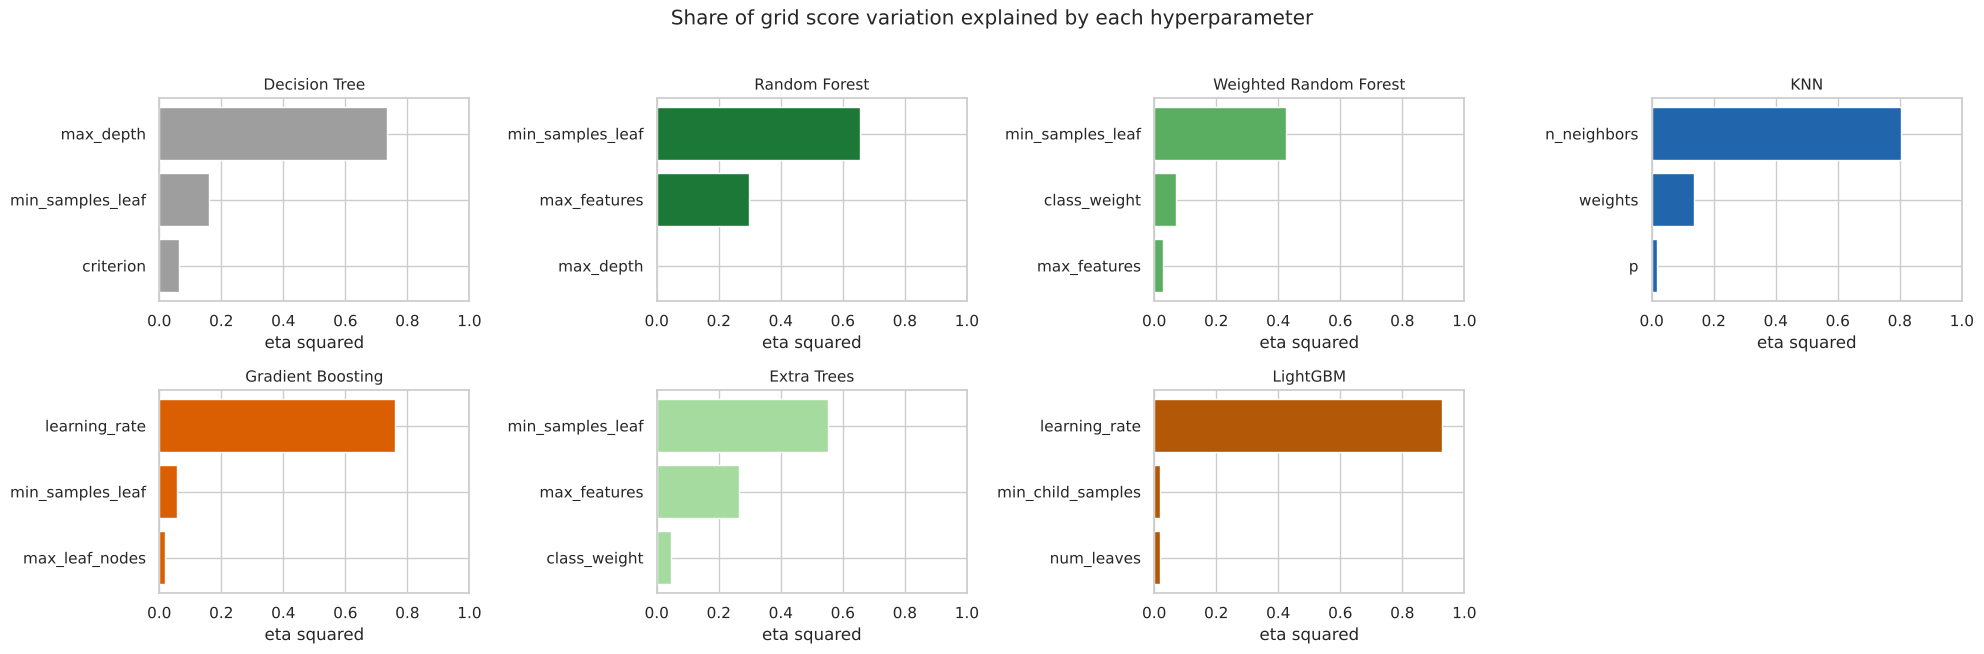

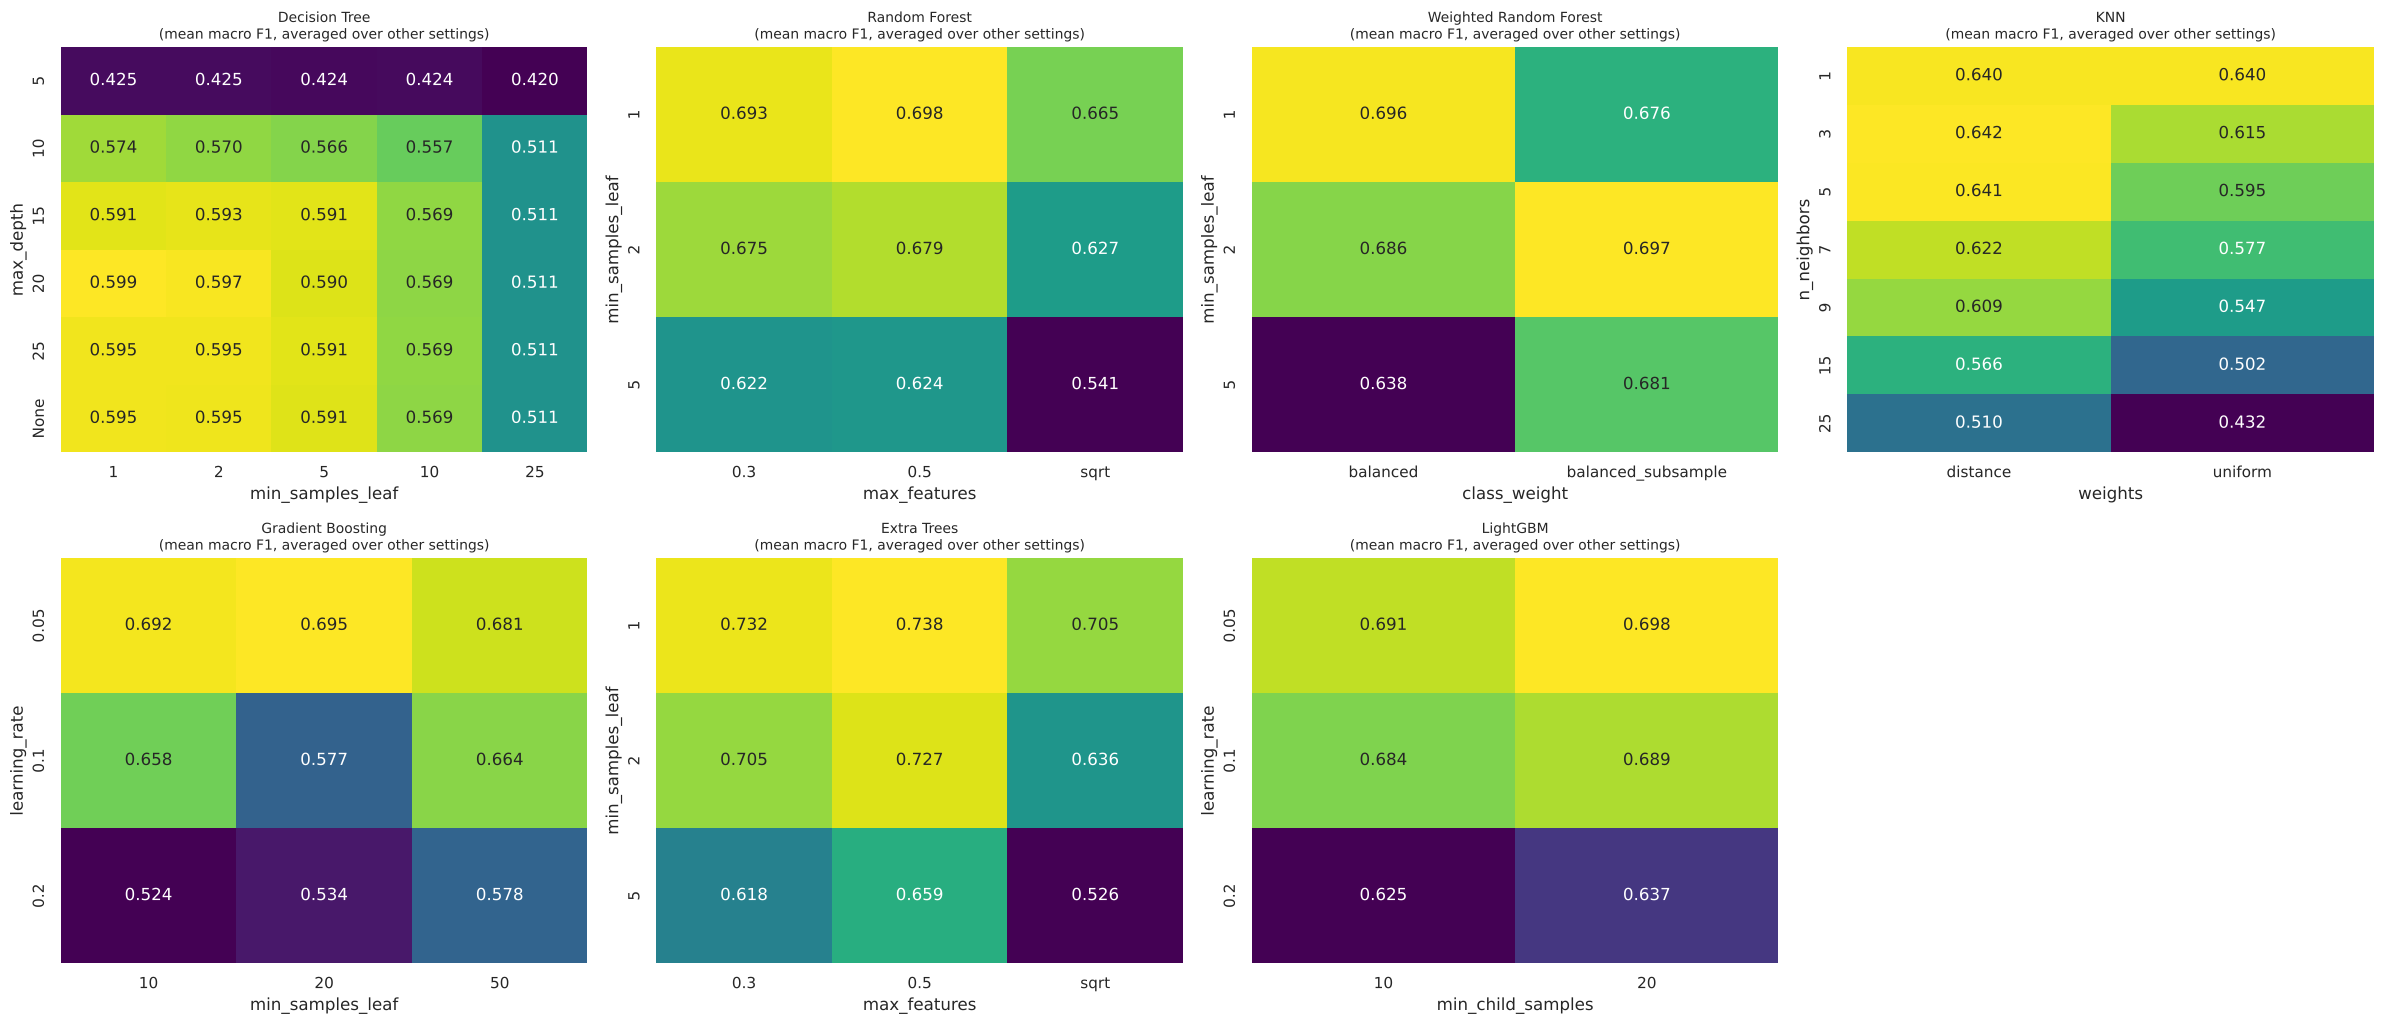

In [ ]:
nrows = int(np.ceil(len(clf_names) / 4))
fig, axes = plt.subplots(nrows, 4, figsize=(20, 3.2 * nrows))
axes = axes.ravel()
for ax in axes[len(clf_names):]:
    ax.set_visible(False)
for ax, name in zip(axes, clf_names):
    a = anova[name].sort_values('eta squared')
    ax.barh(a['hyperparameter'], a['eta squared'], color=model_colors[name])
    ax.set_xlim(0, 1)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('eta squared')
plt.suptitle('Share of grid score variation explained by each hyperparameter', y=1.02)
plt.tight_layout()
plt.show()

def level_order(v):
    # Sort grid levels numerically where possible, with None and text values after the numbers
    try:
        return (0, float(v), '')
    except ValueError:
        return (1, 0.0, v)

fig, axes = plt.subplots(nrows, 4, figsize=(24, 5.2 * nrows))
axes = axes.ravel()
for ax in axes[len(clf_names):]:
    ax.set_visible(False)
for ax, name in zip(axes, clf_names):
    res = grid_results[name]
    top2 = anova[name]['hyperparameter'].head(2).tolist()
    cols = {c.replace('param_', '').split('__')[-1]: c for c in res.columns if c.startswith('param_')}
    piv = res.assign(**{k: [level_name(v) for v in res[cols[k]]] for k in top2}) \
             .pivot_table(index=top2[0], columns=top2[1], values='mean_test_score', aggfunc='mean')
    piv = piv.loc[sorted(piv.index, key=level_order), sorted(piv.columns, key=level_order)]
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar=False)
    ax.set_title(f'{name}\n(mean macro F1, averaged over other settings)', fontsize=10)
plt.tight_layout()
plt.show()

**Parallel speedup.** The decision tree grid took 12.3 seconds on one core and 4.3 seconds on all 24 cores, about 2.9 times faster. That's far short of 24 times because each fit takes only a fraction of a second, so starting the worker processes and collecting their results takes up a large share of the time. The longer fits gain much more, which is why the forest and boosting grids finish many times faster on a machine with more cores.

**Which hyperparameters matter, model by model:**

- **Decision tree.** `max_depth` explains 74% of the score variation. A depth of 5 is far too shallow (macro F1 around 0.42), and everything from depth 15 up, including no limit, sits on a plateau around 0.59. `min_samples_leaf` explains 16%, with a leaf size of 25 clearly too coarse. The split criterion matters least (7%), with entropy a little ahead of gini.
- **Random forest.** `min_samples_leaf` explains 65% and `max_features` explains 30%. Leaf size 1 is best and leaf size 5 costs about 0.07 of macro F1. Trying only the square root of the features at each split is clearly worse than 30% or 50%. `max_depth` doesn't matter at all (eta squared 0.0003, p = 0.79). With 10,000 training rows and leaves of size 1 or more, trees almost never grow past depth 25, so capping them there changes nothing.
- **Weighted random forest.** Nothing dominates here. Only `min_samples_leaf` is significant (43%, p = 0.02), while `class_weight` and `max_features` are not. The main effects add up to only about half of the variation, which means the rest comes from interactions. The heatmap shows one. `balanced` weights work well with leaf size 1 but fall apart with leaf size 5 (0.638), while `balanced_subsample` holds up much better at leaf size 5 (0.681). With heavy weights on rare classes, a larger leaf can swallow the few rare cells it contains.
- **KNN.** `n_neighbors` explains 80%. Smaller is better, and performance slides steadily from k = 3 (0.642 with distance weights) to k = 25 (0.510). Distance weighting explains another 14% and matters more as k grows, since it lets the closest neighbors outvote far ones. The distance metric barely matters (2%).
- **Gradient boosting.** `learning_rate` explains 76%. The slowest rate tried, 0.05, is best and 0.2 is clearly worst. Tree size and leaf size barely matter in this range. We think early stopping is part of the story. With a fast learning rate, each new tree makes big changes, and the small 10% validation slice used for early stopping can stop the model at a bad point. The odd dip at learning rate 0.1 with leaf size 20 (0.577) fits that idea.

- **Extra trees.** `min_samples_leaf` explains 55% and `max_features` explains 27%, the same order as the random forest. Leaf size 1 with half the features at each split is best (0.738), and leaf size 5 with the square root of the features is worst (0.526). Class weights barely matter (4%, p = 0.07).
- **LightGBM.** `learning_rate` explains 93%, the strongest single effect in any of our grids. Rates of 0.05 and 0.1 are close (about 0.68 to 0.70) and 0.2 is clearly worse (about 0.63). Tree size and minimum leaf size hardly matter (under 2% each). This is the same lesson as gradient boosting. For boosting on this data, the learning rate is the setting to get right.

The common thread is that **the hyperparameters that control how much local detail a model can fit matter most**: leaf size for the forests and extra trees, depth for the tree, k for KNN. For the two boosting models it's the learning rate instead. Every model wanted as much local detail as it could get, which matches what we saw earlier. Cover type changes in small patches, and nearby cells are the best evidence for each other.

<a id="sec-5-2-stacking-classifier"></a>
### 5.2 Stacking classifier

Stacking (Wolpert, 1992) trains a second level model on the predictions of several first level models. The idea is that different models make different mistakes, and a model that has watched where each one goes wrong can combine them better than a simple vote.

Our setup:

- **Base models:** the better of our two random forests (by cross validated macro F1), extra trees, KNN, gradient boosting and LightGBM, all with their tuned settings. We skip the single decision tree because it's a weaker version of what the forest already does. The five we picked cover four different ways of learning: bagged trees, randomized trees, nearest neighbors and boosted trees, with two boosting models built in different ways.
- **What the final model sees:** each base model's predicted probability for all seven classes (`stack_method='predict_proba'`), so 35 inputs per row. Probabilities carry more information than votes, since they show how sure each model was.
- **Out of fold training:** `StackingClassifier` creates the inputs for the final model with internal 3 fold cross validation. Each base model's predictions come from data it wasn't trained on, otherwise the final model would learn to trust whichever base model overfits the most.
- **Final model:** scikit-learn's default final model is logistic regression. Since we were asked not to use it, we use a small random forest (200 trees, minimum leaf size 5) instead.

Before training it, we check whether the base models actually make different mistakes on the test set. If they all fail on the same rows, stacking has nothing to work with.

In [ ]:
forest_name = max(['Random Forest', 'Weighted Random Forest'], key=lambda n: cv_clf[n]['test_f1_macro'].mean())
base_names = [forest_name, 'Extra Trees', 'KNN', 'Gradient Boosting', 'LightGBM']

wrong = pd.DataFrame({n: test_pred[n] != y_arr for n in base_names})
n_wrong = wrong.sum(axis=1)
overlap = pd.DataFrame({'rows': n_wrong.value_counts().sort_index(),
                        'percent': (100 * n_wrong.value_counts(normalize=True).sort_index()).round(2)})
overlap.index = [f'{k} of {len(base_names)} base models wrong' for k in overlap.index]
display(overlap)
print('Correlation between the base models\' error indicators:')
display(wrong.astype(int).corr().round(3))
print(f'If we could always pick the right base model, accuracy would be {100 * (n_wrong < len(base_names)).mean():.2f}%')

,rows,percent
0 of 5 base models wrong,412978,77.77
1 of 5 base models wrong,48833,9.20
2 of 5 base models wrong,17970,3.38
3 of 5 base models wrong,14142,2.66
4 of 5 base models wrong,13377,2.52
5 of 5 base models wrong,23712,4.47


Correlation between the base models' error indicators:


,Random Forest,Extra Trees,KNN,Gradient Boosting,LightGBM
Random Forest,1.000,0.734,0.470,0.680,0.698
Extra Trees,0.734,1.000,0.546,0.619,0.654
KNN,0.470,0.546,1.000,0.426,0.443
Gradient Boosting,0.680,0.619,0.426,1.000,0.743
LightGBM,0.698,0.654,0.443,0.743,1.000


If we could always pick the right base model, accuracy would be 95.53%


In [ ]:
stack = StackingClassifier(
    estimators=[('forest', build_model(forest_name)), ('extra', build_model('Extra Trees')),
                ('knn', build_model('KNN')), ('boost', build_model('Gradient Boosting')),
                ('lgbm', build_model('LightGBM'))],
    final_estimator=RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                           random_state=RANDOM_STATE, n_jobs=N_JOBS),
    stack_method='predict_proba',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1)

t0 = time.time(); stack.fit(X_dev_c, y_dev_c); t1 = time.time()
test_pred['Stacking'] = stack.predict(X_test_c); t2 = time.time()
print(f'stacking fit {t1 - t0:.0f}s, predict {t2 - t1:.0f}s')

best_single = test_clf['macro F1'].idxmax()
stack_tbl = pd.DataFrame({n: clf_metrics(y_test_c, test_pred[n]) for n in base_names + ['Stacking']}).T
display(stack_tbl.round(4))

stacking fit 320s, predict 367s


,macro F1,accuracy,balanced accuracy,weighted F1
Random Forest,0.8320,0.8939,0.7977,0.8925
Extra Trees,0.8564,0.9081,0.8316,0.9074
KNN,0.7636,0.8484,0.7511,0.8480
Gradient Boosting,0.8365,0.8863,0.8079,0.8854
LightGBM,0.8453,0.8998,0.8147,0.8989
Stacking,0.8702,0.9134,0.8664,0.9133


Stacking minus Extra Trees: macro F1 difference +0.0138, 95% bootstrap CI [+0.0123, +0.0153]
McNemar: rows only stacking right = 11,222, rows only Extra Trees right = 8,385, chi2 = 410.2, p = 3.31e-91


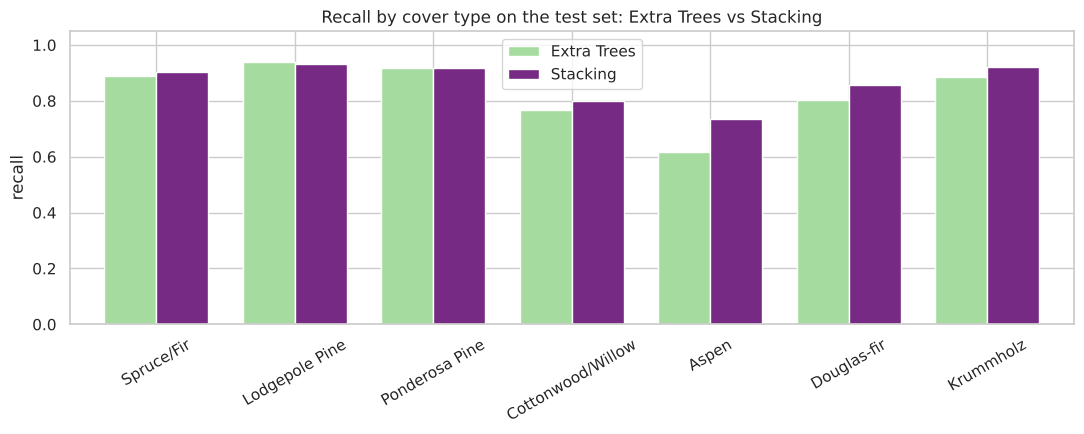

,Extra Trees,Stacking,change
Spruce/Fir,0.8887,0.9034,0.0148
Lodgepole Pine,0.9403,0.9302,-0.0101
Ponderosa Pine,0.9188,0.9189,0.0002
Cottonwood/Willow,0.7658,0.8001,0.0342
Aspen,0.6186,0.7342,0.1156
Douglas-fir,0.8022,0.8577,0.0556
Krummholz,0.8869,0.9204,0.0334


In [ ]:
# Paired bootstrap 95% CI for the test set macro F1 difference (stacking minus best single model).
# Macro F1 is computed from confusion counts with np.bincount so 1,000 resamples run quickly.
def macro_f1_fast(t, p, k=7):
    cm = np.bincount(t * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    return np.mean(np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0))

t_idx = y_arr.astype(int) - 1
s_idx = test_pred['Stacking'].astype(int) - 1
b_idx = test_pred[best_single].astype(int) - 1
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(t_idx), len(t_idx))
    boot.append(macro_f1_fast(t_idx[i], s_idx[i]) - macro_f1_fast(t_idx[i], b_idx[i]))
lo, hi = np.percentile(boot, [2.5, 97.5])
point = macro_f1_fast(t_idx, s_idx) - macro_f1_fast(t_idx, b_idx)
only_s, only_b, chi2, p = mcnemar(y_arr, test_pred['Stacking'], test_pred[best_single])
print(f'Stacking minus {best_single}: macro F1 difference {point:+.4f}, 95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]')
print(f'McNemar: rows only stacking right = {only_s:,}, rows only {best_single} right = {only_b:,}, chi2 = {chi2:.1f}, p = {p:.3g}')

rec = pd.DataFrame({n: recall_score(y_test_c, test_pred[n], average=None, labels=list(cover_type_names))
                    for n in [best_single, 'Stacking']}, index=class_labels)
ax = rec.plot.bar(figsize=(11, 4.5), color=[model_colors[best_single], model_colors['Stacking']], width=0.75)
ax.set_title(f'Recall by cover type on the test set: {best_single} vs Stacking')
ax.set_ylim(0, 1.05); ax.set_ylabel('recall'); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
display((rec.assign(change=rec['Stacking'] - rec[best_single])).round(4))

**Do the base models make different mistakes?** Yes, enough to be worth stacking. All five are right on 77.8% of test cells and all five are wrong on 4.5%. The remaining 18% are cells where they disagree, and those are the cells stacking can improve. The error correlation table shows where the variety comes from. The two boosting models fail on the most similar cells (correlation 0.74), and so do the random forest and extra trees (0.73), which makes sense since each pair is built the same basic way. KNN's errors are much less related to the others (0.43 to 0.55), so even though KNN is the weakest model on its own, it adds the most new information to the stack. If we could somehow always pick the right base model for each cell, accuracy would reach 95.5%. That's the ceiling stacking is trying to approach.

**Did it work?** It did. The stacking classifier beats every single model on every metric: macro F1 0.870, accuracy 91.3% and balanced accuracy 0.866. Against extra trees, our best single model, the gain is +0.014 with a 95% paired bootstrap confidence interval of 0.012 to 0.015, which doesn't come close to zero. McNemar's test agrees. Stacking is right on 11,222 test cells where extra trees is wrong, while the reverse happens on 8,385 cells.

The gains land where the single models were weakest. Aspen recall goes up by 12 points (0.62 to 0.73), Douglas-fir by 6 points and Cottonwood/Willow and Krummholz by about 3 points each. These are exactly the classes where the base models disagreed most. The one small cost is Lodgepole Pine, whose recall drops by 1 point, likely because the stack is now more willing to call a borderline cell Aspen.

**The cost.** Stacking took many times longer to train and predict than extra trees alone, mostly because of KNN and the extra base models. For a one time map that's fine. For something that runs over a huge area every week, a team would need to decide whether a gain of about 1.4 points in macro F1 is worth that much more compute.

One more comparison puts this in perspective. The training size check in Section 3.5 showed that a single tuned random forest trained on about 349,000 rows reaches a macro F1 of 0.928, well above this stack at 0.870. With a fixed amount of labeled data, stacking is a good way to get more out of it. If more labeled data is available, using it beats stacking by a wide margin.

It's also worth noting that this is the one place KNN earned its keep. Alone it tied with a single decision tree. Inside the stack its different way of seeing the data helped the final model fix mistakes the four tree ensembles shared.

<a id="sec-6-references"></a>
## 6. References

Blackard, J. A. (1998). *Covertype* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50K5N

Blackard, J. A., & Dean, D. J. (1999). Comparative accuracies of artificial neural networks and discriminant analysis in predicting forest cover types from cartographic variables. *Computers and Electronics in Agriculture, 24*(3), 131-151.

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32.

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Chen, C., Liaw, A., & Breiman, L. (2004). *Using random forest to learn imbalanced data* (Technical Report 666). Department of Statistics, University of California, Berkeley.

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794.

Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21-27.

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895-1923.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232.

Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3-42.

Ghosh, M. (2026). *Random forest and weighted random forest models on Covertype* [Unpublished Jupyter notebook]. MSDS 7331 Group 3, Southern Methodist University. (Source of the classification reports, the Aspen error breakdown by wilderness area, and the 60/20/20 split and fixed forest settings used in our training size check.)

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65-70.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.

McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika, 12*(2), 153-157.

Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3), 239-281.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*.

Raschka, S. (2015). *Python machine learning*. Packt Publishing. (Course text. Chapter 3 for decision trees, random forests and KNN, Chapter 4 for feature scaling, L1 regularization and random forest feature importance, Chapter 6 for pipelines, k fold cross validation, grid search and multiclass metrics, Chapter 7 for ensemble methods, Chapter 10 for regularized regression.)

Shearer, C. (2000). The CRISP-DM model: The new blueprint for data mining. *Journal of Data Warehousing, 5*(4), 13-22.

Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics, 8*, 25.

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241-259.

Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301-320.

**Software documentation.** scikit-learn User Guide sections on cross validation, grid search, permutation feature importance, `HistGradientBoostingClassifier`, `ExtraTreesClassifier` and `StackingClassifier` (https://scikit-learn.org/stable/user_guide.html). The `ucimlrepo` package for loading the data (https://github.com/uci-ml-repo/ucimlrepo). The LightGBM documentation (https://lightgbm.readthedocs.io) for its scikit-learn interface, early stopping callback and deterministic training options.

**Our earlier work.** The `Aspect` sine and cosine encoding, the class color scheme and the decision to leave out the ELU zone features come from our Lab One and Mini Lab notebooks on this dataset.